# 📘 Estudo de caso: atraso, cancelamento e reclamações na aviação brasileira
### A trilha do Manual de Análise de Dados aplicada a dados reais da ANAC

> **Atraso e cancelamento explicam as reclamações? Quanto cada ponto de pontualidade reduz as reclamações por 100 mil passageiros, e qual companhia converte mais problema operacional em reclamação não resolvida?**

Fonte: ANAC (dados abertos). Código sob licença MIT; textos e gráficos sob CC BY 4.0. Site: https://manual-analise-de-dados.vercel.app/estudo-de-caso/

## 0. Pergunta de negócio, dados e abordagem

Azul, Gol e LATAM transportaram mais de 99 % dos passageiros domésticos pagos do Brasil em 2025. Todas publicam, por obrigação regulatória, o horário previsto e o realizado de cada voo, e todas recebem reclamações no consumidor.gov.br. Dá para juntar as duas pontas e perguntar:

1. **Atraso e cancelamento explicam as reclamações?** Ou as reclamações dependem de outras coisas (reembolso, cobrança, atendimento)?
2. **Quanto vale um ponto de pontualidade?** Em reclamações por 100 mil passageiros pagos, com intervalo de confiança.
3. **Qual companhia converte mais problema operacional em reclamação não resolvida?**

E, para a operação: **dá para prever o risco de atraso só com o que se sabe na hora de montar a malha?**

**Fontes (todas da ANAC, dados abertos)**

| Fonte | O que traz | Grão | Período usado |
|---|---|---|---|
| [VRA, Voo Regular Ativo](https://www.gov.br/anac/pt-br/acesso-a-informacao/dados-abertos/areas-de-atuacao/voos-e-operacoes-aereas/voo-regular-ativo-vra/62-voo-regular-ativo-vra) | partida e chegada previstas e realizadas, situação do voo | uma etapa de voo | jan/2023 a ago/2026 |
| [Dados Estatísticos do Transporte Aéreo](https://sistemas.anac.gov.br/dadosabertos/Voos%20e%20opera%C3%A7%C3%B5es%20a%C3%A9reas/Dados%20Estat%C3%ADsticos%20do%20Transporte%20A%C3%A9reo/) | passageiros pagos, assentos, ASK e RPK | companhia × mês × rota | jan/2023 a ago/2026 |
| [Reclamações do consumidor.gov.br](https://sistemas.anac.gov.br/dadosabertos/Voos%20e%20opera%C3%A7%C3%B5es%20a%C3%A9reas/Dados%20do%20consumidor.gov/) | problema, resposta, avaliação e nota de cada reclamação | uma reclamação | jan/2023 a dez/2025 (último ano publicado) |

**Abordagem, na ordem da trilha do manual**

| Módulo da trilha | Seções | O que se faz aqui |
|---|---|---|
| Preparar | 1 a 4 | download reproduzível com hash, leitura dos CSVs, modelo estrela em DuckDB (SQL versionado), qualidade e de-para das companhias |
| Explorar | 5 a 7 | KPIs de pontualidade e cancelamento, outliers, sazonalidade, reclamações por 100 mil passageiros e funil da reclamação |
| Inferir | 8 e 9 | testes de proporções e qui-quadrado; regressão no painel companhia × mês, com controles e um teste placebo |
| Machine Learning | 10 | classificador de risco de atraso com validação temporal e sem vazamento |
| Comunicar | 11 e 12 | três achados quantificados, recomendações e limites |

**Como reproduzir** (a partir da pasta `site/` do repositório): `gerador/.venv/bin/python gerador/estudo-de-caso/baixar_dados.py` baixa cerca de 1 GB para `gerador/estudo-de-caso/dados/` (fora do git) e `npm run gerar:caso` executa este notebook e atualiza o site. O notebook leva cerca de 2 minutos para rodar, além do download.

## 1. Configuração do ambiente

### 1.1 Bibliotecas e tema dos gráficos

**O que faz:** carrega as bibliotecas e aplica aos gráficos o tema do design system do manual (o mesmo das demais páginas).

In [1]:
import json
import sys
import warnings
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from IPython.display import Markdown, display
from scipy import stats
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, brier_score_loss, precision_recall_curve,
                             roc_auc_score, roc_curve)
from statsmodels.stats.proportion import proportion_confint, proportions_ztest

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=DeprecationWarning)

sys.path.insert(0, str(Path.cwd().parent))   # gerador/: tema do design system
import tema
exec(tema.CELULA_TEMA)                         # fontes, paletas ds_seq/ds_div e cores do tema escuro
pd.set_option('display.max_columns', 30)

### 1.2 Parâmetros do projeto

Todas as escolhas que mudam o resultado ficam aqui, com nome: o período, os limiares de atraso e as datas de corte do modelo.

In [2]:
PERIODO_VOOS = ('2023-01', '2026-08')        # VRA e Dados Estatísticos
FIM_RECLAMACOES = '2025-12-01'               # último mês publicado do consumidor.gov.br (19/10/2026)
LIMIAR_ATRASO = 15                           # minutos: KPI de pontualidade (partida e chegada)
LIMIAR_ATRASO_ML = 30                        # minutos: alvo do classificador
LIMIAR_OUTLIER = 240                         # minutos: atraso extremo (4 h)
CORTE_VALIDACAO = '2025-07-01'               # treino até jun/2025, validação jul–dez/2025
CORTE_TESTE = '2026-01-01'                   # teste: jan–ago/2026, usado uma única vez
SEMENTE = 42

PASTA_SQL = Path('sql')
PASTA_AGREGADOS = Path('agregados')
EMPRESAS = ['Azul', 'Gol', 'LATAM']
CORES = dict(zip(EMPRESAS, [tema.CIANO, tema.VERDE, tema.ROXO]))
FONTE = 'Fonte: ANAC (dados abertos). Elaboração própria.'


def fonte(fig, texto=FONTE):
    """Crédito da fonte no rodapé do gráfico, abaixo de tudo o que já foi desenhado (rótulos dos eixos inclusive)."""
    fig.canvas.draw()
    base = fig.get_tightbbox(fig.canvas.get_renderer()).y0 / fig.get_figheight()
    fig.text(0.99, base - 0.015, texto, ha='right', va='top', fontsize=8, color=tema.TEXTO_2)


def br(x, casas=1):
    """Número no formato brasileiro: 1.234,5."""
    return f'{x:,.{casas}f}'.replace(',', '_').replace('.', ',').replace('_', '.')


def tabela(df, casas=1):
    """Copia do DataFrame com os números formatados em pt-BR, para exibir."""
    saida = df.copy()
    for c in saida.columns:
        if pd.api.types.is_float_dtype(saida[c]):
            saida[c] = saida[c].map(lambda v: '' if pd.isna(v) else br(v, casas))
        elif pd.api.types.is_integer_dtype(saida[c]):
            saida[c] = saida[c].map(lambda v: br(v, 0))
    return saida


def mostrar_sql(arquivo):
    """Exibe o arquivo SQL versionado exatamente como ele é executado."""
    return Markdown(f"```sql\n{(PASTA_SQL / arquivo).read_text(encoding='utf-8').strip()}\n```")

## 2. Download e importação dos dados

### 2.1 Download reproduzível

**O que faz:** baixa os arquivos do período, guarda em `dados/` (pasta fora do git) e registra URL, tamanho e SHA-256 de cada um em `manifesto_download.json`, que é versionado.

**Quando usar:** sempre que a fonte é pública e grande demais para ir para o repositório. O manifesto mostra se uma nova execução recebeu os mesmos arquivos: a ANAC atualiza os CSVs (a primeira linha de cada um diz quando).

⚠️ **O que observar**
- Os dados brutos não vão para o git. Só os agregados pequenos de `agregados/` são versionados, com o crédito à ANAC.
- O script só baixa o que falta. Para baixar de novo, use `--forcar`.

In [3]:
import baixar_dados

manifesto = baixar_dados.main(*[p for p in PERIODO_VOOS])
arquivos = pd.DataFrame(manifesto['arquivos'])
arquivos['fonte'] = arquivos['arquivo'].str.split('/').str[0].map(
    {'vra': 'VRA', 'estatisticas': 'Dados Estatísticos', 'reclamacoes': 'consumidor.gov.br'})
resumo_download = (arquivos.groupby('fonte', sort=False)
                   .agg(arquivos=('arquivo', 'size'), MB=('bytes', lambda b: b.sum() / 1e6),
                        primeiro=('arquivo', 'first'), sha256_do_primeiro=('sha256', lambda s: s.iloc[0][:16] + '…'))
                   .reset_index())
tabela(resumo_download, 0)

48 arquivos, 991 MB em estudo-de-caso/dados/


,fonte,arquivos,MB,primeiro,sha256_do_primeiro
0,VRA,44,514,vra/VRA_202301.csv,bf05d93b9ea81b8b…
1,Dados Estatísticos,1,360,estatisticas/Dados_Estatisticos.csv,85731298fc266d1e…
2,consumidor.gov.br,3,117,reclamacoes/dadosconsumidor2023.csv,f63f38ba3a9a7f8d…


### 2.2 Formato dos arquivos

Os três arquivos seguem o mesmo padrão, que quebra a leitura direta: UTF-8 **com BOM**, uma primeira linha que não é cabeçalho (`Atualizado em: AAAA-MM-DD`), separador `;` e o texto `null` no lugar de valor ausente.

In [4]:
with open('dados/vra/VRA_202608.csv', 'rb') as f:
    for _ in range(3):
        print(f.readline()[:160])

b'\xef\xbb\xbfAtualizado em: 2026-10-07\r\n'
b'"ICAO Empresa A\xc3\xa9rea";"N\xc3\xbamero Voo";"C\xc3\xb3digo Autoriza\xc3\xa7\xc3\xa3o (DI)";"C\xc3\xb3digo Tipo Linha";"ICAO Aer\xc3\xb3dromo Origem";"ICAO Aer\xc3\xb3dromo Destino";"Partida Prevista";"Par'
b'"TAP";"0084";"0";"I";"SBGR";"LPPT";"2026-08-02 01:05:00";"2026-08-02 01:05:00";"2026-08-02 10:55:00";"2026-08-02 10:40:00";"REALIZADO";"N/A"\r\n'


A leitura fica no SQL: `skip=1` pula a linha extra, `nullstr='null'` reconhece os ausentes e tudo entra como texto (`all_varchar`), para que cada conversão de tipo seja feita, à vista, nas tabelas de fato.

In [5]:
mostrar_sql('01_staging.sql')

```sql
-- 01_staging.sql: leitura dos CSVs da ANAC, sem transformar o conteúdo.
-- Executado a partir de gerador/estudo-de-caso/ (os caminhos são relativos a essa pasta).
--
-- Os três arquivos têm o mesmo formato: UTF-8 com BOM, uma primeira linha "Atualizado em: AAAA-MM-DD"
-- (pulada com skip=1), separador ";", aspas duplas e o texto "null" no lugar de valor ausente.
-- Tudo é lido como texto (all_varchar): os tipos são definidos nas tabelas de fato, onde cada
-- conversão fica visível.

CREATE OR REPLACE VIEW stg_vra AS
SELECT *
FROM read_csv('dados/vra/VRA_*.csv',
              skip = 1, header = true, delim = ';', quote = '"',
              nullstr = 'null', all_varchar = true, filename = true);

CREATE OR REPLACE VIEW stg_estatistica AS
SELECT *
FROM read_csv('dados/estatisticas/Dados_Estatisticos.csv',
              skip = 1, header = true, delim = ';', quote = '"',
              nullstr = ['null', ''], all_varchar = true)
WHERE CAST(ANO AS INTEGER) >= 2023;           -- o arquivo vai de 2000 até hoje

CREATE OR REPLACE VIEW stg_reclamacao AS
SELECT *
FROM read_csv('dados/reclamacoes/dadosconsumidor*.csv',
              skip = 1, header = true, delim = ';', quote = '"',
              nullstr = 'null', all_varchar = true, union_by_name = true);
```

### 2.3 Modelo estrela em DuckDB

**O que faz:** organiza as três fontes em fatos (eventos que se contam) e dimensões (como se filtra e agrupa), num banco DuckDB local. O SQL fica em arquivos versionados em `sql/`, executados em ordem.

| Tabela | Tipo | Grão |
|---|---|---|
| `fato_voo` | fato | uma etapa de voo doméstico (VRA) |
| `fato_estatistica_mes` | fato | companhia × mês × natureza (doméstica ou internacional) |
| `fato_reclamacao` | fato | uma reclamação no consumidor.gov.br |
| `dim_empresa` | dimensão | companhia (de-para ICAO ↔ Nome Fantasia) |
| `dim_aerodromo` | dimensão | aeródromo (código ICAO, UF, região) |
| `dim_data` | dimensão | dia |
| `mart_empresa_mes` | tabela analítica | companhia × mês, com as três fontes juntas |

⚠️ **O que observar**
- A ligação entre voos e reclamações só existe no nível **companhia × mês**: a reclamação não traz o número do voo.
- O arquivo de Dados Estatísticos tem 360 MB e vai de 2000 até hoje; o filtro de anos é feito na leitura.

In [6]:
Path('dados').mkdir(exist_ok=True)
con = duckdb.connect('dados/anac.duckdb')      # banco local, fora do git
for arquivo in ['01_staging.sql', '02_dimensoes.sql', '03_fatos.sql', '04_marts.sql']:
    con.execute((PASTA_SQL / arquivo).read_text(encoding='utf-8'))


def q(sql):
    """Consulta SQL -> DataFrame."""
    return con.sql(sql).df()


tabela(q('''
    SELECT table_name AS tabela, estimated_size AS linhas, column_count AS colunas
    FROM duckdb_tables() ORDER BY table_name
'''), 0)

,tabela,linhas,colunas
0,dim_aerodromo,584,5
1,dim_data,1.461,6
2,dim_empresa,3,3
3,fato_estatistica_mes,2.677,9
4,fato_reclamacao,290.139,11
5,fato_voo,2.867.420,17
6,mart_empresa_mes,133,28


In [7]:
mostrar_sql('03_fatos.sql')

```sql
-- 03_fatos.sql: tabelas de fato, com os tipos definidos e as regras de qualidade explícitas.

-- fato_voo: uma linha por etapa de voo (VRA), só linhas domésticas (Código Tipo Linha = 'N').
CREATE OR REPLACE TABLE fato_voo AS
WITH tipado AS (
    SELECT
        "ICAO Empresa Aérea"     AS empresa_icao,
        "Número Voo"             AS numero_voo,
        "Código Tipo Linha"      AS tipo_linha,
        "ICAO Aeródromo Origem"  AS origem_icao,
        "ICAO Aeródromo Destino" AS destino_icao,
        try_strptime("Partida Prevista", '%Y-%m-%d %H:%M:%S') AS partida_prevista,
        try_strptime("Partida Real",     '%Y-%m-%d %H:%M:%S') AS partida_real,
        try_strptime("Chegada Prevista", '%Y-%m-%d %H:%M:%S') AS chegada_prevista,
        try_strptime("Chegada Real",     '%Y-%m-%d %H:%M:%S') AS chegada_real,
        "Situação Voo"           AS situacao,
        "Código Justificativa"   AS justificativa
    FROM stg_vra
    WHERE "Código Tipo Linha" = 'N'
),
bruto AS (
    SELECT
        *,
        situacao = 'REALIZADO' AND partida_real IS NOT NULL AND chegada_real IS NOT NULL AS tem_horario_real,
        date_diff('minute', partida_prevista, partida_real)  AS atraso_partida_bruto,
        date_diff('minute', chegada_prevista, chegada_real)  AS atraso_chegada_bruto
    FROM tipado
),
corrigido AS (
    -- virada de dia: voo previsto para 23h50 que sai às 00h56 às vezes aparece com a data real do dia
    -- anterior, o que dá um "adiantamento" de cerca de -1.374 min. Menos de -12 h só pode ser isso: soma 24 h.
    SELECT
        *,
        atraso_partida_bruto < -720 OR atraso_chegada_bruto < -720                AS corrigido_virada_dia,
        atraso_partida_bruto + CASE WHEN atraso_partida_bruto < -720 THEN 1440 ELSE 0 END AS atraso_partida_corr,
        atraso_chegada_bruto + CASE WHEN atraso_chegada_bruto < -720 THEN 1440 ELSE 0 END AS atraso_chegada_corr
    FROM bruto
),
validado AS (
    -- horário real válido: voo realizado, com os dois horários reais e atrasos plausíveis depois da correção
    -- (partida até 2 h adiantada e chegada até 3 h adiantada; atraso de no máximo 24 h)
    SELECT
        *,
        tem_horario_real
            AND atraso_partida_corr BETWEEN -120 AND 1440
            AND atraso_chegada_corr BETWEEN -180 AND 1440
            AND chegada_real > partida_real                                         AS horario_real_valido
    FROM corrigido
)
SELECT
    empresa_icao, numero_voo, origem_icao, destino_icao,
    CAST(partida_prevista AS DATE)                                      AS data_id,
    hour(partida_prevista)                                              AS hora_prevista,
    partida_prevista, partida_real, chegada_prevista, chegada_real,
    situacao, justificativa, tem_horario_real, corrigido_virada_dia, horario_real_valido,
    CASE WHEN horario_real_valido THEN atraso_partida_corr END          AS atraso_partida_min,
    CASE WHEN horario_real_valido THEN atraso_chegada_corr END          AS atraso_chegada_min
FROM validado
WHERE partida_prevista IS NOT NULL;

-- fato_estatistica_mes: passageiros e oferta por empresa, mês e natureza (doméstica ou internacional).
CREATE OR REPLACE TABLE fato_estatistica_mes AS
SELECT
    EMPRESA_SIGLA                                                   AS empresa_icao,
    CAST(ANO AS INTEGER)                                            AS ano,
    CAST(MES AS INTEGER)                                            AS mes,
    NATUREZA                                                        AS natureza,
    SUM(CAST(PASSAGEIROS_PAGOS AS BIGINT))                          AS passageiros_pagos,
    SUM(CAST(ASSENTOS AS BIGINT))                                   AS assentos,
    SUM(CAST(DECOLAGENS AS BIGINT))                                 AS decolagens,
    SUM(CAST(replace(RPK, ',', '.') AS DOUBLE))                     AS rpk,
    SUM(CAST(replace(ASK, ',', '.') AS DOUBLE))                     AS ask
FROM stg_estatistica
WHERE GRUPO_DE_VOO = 'REGULAR'
GROUP BY ALL;

-- fato_reclamacao: uma linha por reclamação no consumidor.gov.br.
CREATE OR REPLACE TABLE fato_reclamacao AS
SELECT
    "Nome Fantasia"                                                 AS nome_fantasia,
    CAST("Data Abertura" AS DATE)                                   AS data_id,
    "UF"                                                            AS uf,
    "Grupo Problema"                                                AS grupo_problema,
    "Problema"                                                      AS problema,
    -- problema operacional: o motivo da reclamação é o próprio atraso, cancelamento ou interrupção do voo
    regexp_matches("Problema", 'Atraso de voo|Cancelamento de voo|interrupção de voo') AS problema_operacional,
    "Respondida" = 'S'                                              AS respondida,
    "Situação"                                                      AS situacao,
    "Avaliação Reclamação"                                          AS avaliacao,
    TRY_CAST("Nota do Consumidor" AS INTEGER)                       AS nota,
    TRY_CAST("Tempo Resposta (em dias)" AS INTEGER)                 AS tempo_resposta_dias
FROM stg_reclamacao;
```

## 3. Primeira inspeção e qualidade

### 3.1 Estrutura da tabela de voos

In [8]:
q('''
    SELECT empresa_icao, numero_voo, origem_icao, destino_icao, partida_prevista, partida_real,
           chegada_prevista, chegada_real, situacao, justificativa, atraso_partida_min, atraso_chegada_min
    FROM fato_voo JOIN dim_empresa USING (empresa_icao)
    USING SAMPLE reservoir(5 ROWS) REPEATABLE (42)
''')

,empresa_icao,numero_voo,origem_icao,destino_icao,partida_prevista,partida_real,chegada_prevista,chegada_real,situacao,justificativa,atraso_partida_min,atraso_chegada_min
0,AZU,4861,SBEG,SBBE,2023-01-20 22:50:00,2023-01-20 22:50:00,2023-01-21 01:00:00,2023-01-21 00:55:00,REALIZADO,N/A,0,-5
1,AZU,2737,SBAR,SBRF,2023-01-12 10:15:00,2023-01-12 10:05:00,2023-01-12 11:15:00,2023-01-12 11:01:00,REALIZADO,N/A,-10,-14
2,GLO,1171,SBFI,SBGR,2023-01-18 18:10:00,2023-01-18 18:41:00,2023-01-18 19:55:00,2023-01-18 20:27:00,REALIZADO,N/A,31,32
3,AZU,2778,SBSV,SBIL,2023-01-22 14:05:00,2023-01-22 13:53:00,2023-01-22 14:55:00,2023-01-22 14:46:00,REALIZADO,N/A,-12,-9
4,AZU,4350,SBKP,SBRJ,2023-01-11 09:00:00,2023-01-11 09:08:00,2023-01-11 10:05:00,2023-01-11 10:22:00,REALIZADO,N/A,8,17


### 3.2 O campo de justificativa está vazio

O VRA tinha um código de justificativa para cada atraso ou cancelamento (clima, manutenção, tráfego aéreo…). O campo deixou de ser exigido em abril de 2020, com a revogação da IAC 1504.

In [9]:
tabela(q('''
    SELECT justificativa, count(*) AS voos, 100.0 * count(*) / sum(count(*)) OVER () AS pct
    FROM fato_voo GROUP BY ALL ORDER BY voos DESC
'''))

,justificativa,voos,pct
0,N/A,2.867.420,"100,0"


⚠️ **Consequência:** não dá para separar o atraso por clima (que a companhia não controla) do atraso por culpa da companhia. Toda comparação de pontualidade entre companhias nesta análise mistura as duas causas.

### 3.3 Horários reais: ausentes, virada de dia e valores impossíveis

**O que faz:** confere se cada voo realizado tem horário real e se o atraso calculado é plausível.

In [10]:
qualidade = q('''
    SELECT situacao,
           count(*)                                                    AS voos,
           count(*) FILTER (WHERE NOT tem_horario_real)                AS sem_horario_real,
           count(*) FILTER (WHERE corrigido_virada_dia)                AS corrigidos_virada_dia,
           count(*) FILTER (WHERE tem_horario_real AND NOT horario_real_valido) AS implausiveis_excluidos
    FROM fato_voo JOIN dim_empresa USING (empresa_icao)
    GROUP BY ALL ORDER BY voos DESC
''')
tabela(qualidade, 0)

,situacao,voos,sem_horario_real,corrigidos_virada_dia,implausiveis_excluidos
0,REALIZADO,2.699.100,0,391,84
1,CANCELADO,52.410,52.410,0,0


In [11]:
q('''
    SELECT empresa_icao, numero_voo, origem_icao, destino_icao, partida_prevista, partida_real,
           date_diff('minute', partida_prevista, partida_real) AS atraso_bruto_min, atraso_partida_min
    FROM fato_voo WHERE corrigido_virada_dia AND empresa_icao = 'GLO'
    ORDER BY partida_prevista LIMIT 4
''')

,empresa_icao,numero_voo,origem_icao,destino_icao,partida_prevista,partida_real,atraso_bruto_min,atraso_partida_min
0,GLO,1864,SBGL,SBFZ,2023-01-03 23:50:00,2023-01-03 00:56:00,-1374,66
1,GLO,2044,SBGL,SBSG,2023-01-03 23:55:00,2023-01-03 00:07:00,-1428,12
2,GLO,1686,SBGR,SBVC,2023-01-05 23:25:00,2023-01-05 00:37:00,-1368,72
3,GLO,9056,SBVT,SBSV,2023-01-05 23:40:00,2023-01-05 00:09:00,-1411,29


⚠️ **O que observar**
- Os voos sem horário real são **os cancelados**, e só eles: nenhum voo `REALIZADO` está sem horário real no período. A taxa de ausentes do arquivo inteiro (cerca de 3 % em agosto de 2026) é a taxa de cancelamento, não uma falha de registro.
- O defeito real é outro: voos previstos para perto da meia-noite que partem depois dela às vezes aparecem com a **data do dia anterior** no horário real. O atraso calculado vira um "adiantamento" de quase 24 horas (−1.374 min no exemplo). A regra do `03_fatos.sql` soma 24 horas a qualquer diferença menor que −12 horas.
- Depois da correção, atrasos fora de −2 h a +24 h são tratados como implausíveis e saem dos KPIs de pontualidade (o voo continua contando como realizado).

### 3.4 Reclamações: quantas foram avaliadas pelo consumidor

In [12]:
avaliacao_ano = q('''
    SELECT year(data_id) AS ano, coalesce(avaliacao, '(campo vazio)') AS avaliacao, count(*) AS reclamacoes
    FROM fato_reclamacao GROUP BY ALL
''').pivot(index='avaliacao', columns='ano', values='reclamacoes')
pct_avaliacao = 100 * avaliacao_ano / avaliacao_ano.sum()
nao_avaliada_2025 = pct_avaliacao.loc['Não Avaliada', 2025]
tabela(pct_avaliacao.reset_index().rename_axis(None, axis=1))

,avaliacao,2023,2024,2025
0,(campo vazio),"0,0","29,8","0,0"
1,Não Avaliada,"44,3","18,9","49,6"
2,Não Resolvida,"16,8","13,2","16,1"
3,Resolvida,"38,9","38,1","34,3"


⚠️ **O que observar:** cerca de metade das reclamações termina sem que o consumidor diga se foi resolvida. Em 2024 o padrão é outro: perto de 30 % estão com a situação "Respondida" e o campo de avaliação vazio, o que soma, na prática, à parte não avaliada. "Resolvida" e "não resolvida" só valem para a parte avaliada, que não é uma amostra aleatória (quem teve o problema resolvido pode ter menos motivo para voltar e avaliar, ou mais).

### 3.5 Cobertura: as três companhias e o resto do mercado

In [13]:
cobertura = q('''
    SELECT ano, coalesce(e.empresa, 'Outras') AS empresa, sum(passageiros_pagos) AS passageiros
    FROM fato_estatistica_mes AS s LEFT JOIN dim_empresa AS e USING (empresa_icao)
    WHERE natureza = 'DOMÉSTICA' GROUP BY ALL
''').pivot(index='empresa', columns='ano', values='passageiros')
participacao = 100 * cobertura / cobertura.sum()
tabela(participacao.reset_index().rename_axis(None, axis=1), 2)

,empresa,2023,2024,2025,2026
0,Azul,"30,41","31,07","29,69","28,12"
1,Gol,"32,00","29,60","30,83","32,08"
2,LATAM,"36,63","38,34","39,30","39,75"
3,Outras,"0,96","0,99","0,18","0,05"


## 4. Limpeza e tratamento

### 4.1 De-para entre o código ICAO e o nome no consumidor.gov.br

**O que faz:** liga as fontes que identificam a companhia de formas diferentes. O VRA e os Dados Estatísticos usam o código ICAO (`AZU`, `GLO`, `TAM`); o consumidor.gov.br usa o Nome Fantasia. O de-para fica num CSV versionado, `sql/de_para_empresas.csv`.

In [14]:
q('SELECT * FROM dim_empresa')

,empresa_icao,empresa,nome_fantasia_consumidor
0,AZU,Azul,Azul Linhas Aéreas
1,GLO,Gol,Gol Linhas Aéreas
2,TAM,LATAM,Latam Airlines (Tam)


In [15]:
# Conferência: os nomes parecidos estão todos ligados; os que sobram são de outras companhias
tabela(q('''
    SELECT nome_fantasia, count(*) AS reclamacoes, bool_or(e.empresa IS NOT NULL) AS ligado_ao_icao
    FROM fato_reclamacao AS r LEFT JOIN dim_empresa AS e ON r.nome_fantasia = e.nome_fantasia_consumidor
    WHERE regexp_matches(lower(nome_fantasia), 'azul|gol|latam|tam')
    GROUP BY ALL ORDER BY reclamacoes DESC
'''), 0)

,nome_fantasia,reclamacoes,ligado_ao_icao
0,Latam Airlines (Tam),90.612,True
1,Azul Linhas Aéreas,87.081,True
2,Gol Linhas Aéreas,60.465,True
3,TAAG - Linhas Aéreas de Angola,363,False


### 4.2 Escopo

- **Voos:** só linhas domésticas (`Código Tipo Linha = 'N'`) de Azul, Gol e LATAM, que somam mais de 99 % dos passageiros domésticos pagos.
- **Pontualidade:** atraso maior que 15 minutos, na partida e na chegada, entre os voos realizados com horário real válido. Cancelamento: cancelados ÷ (realizados + cancelados).
- **Reclamações por 100 mil passageiros:** o denominador é o total de passageiros pagos da companhia (doméstico e internacional), porque a reclamação não diz se o voo era doméstico.
- **Reclamação operacional:** o problema declarado é o próprio voo: "Atraso de voo", "Cancelamento de voo" e as duas categorias de falta de informação ou assistência em atraso, cancelamento ou interrupção.

### 4.3 Tabela analítica companhia × mês

In [16]:
mostrar_sql('04_marts.sql')

```sql
-- 04_marts.sql: tabela analítica companhia × mês, que junta as três fontes.
-- A ligação entre voos e reclamações só existe neste nível: o consumidor.gov.br não traz o número do voo.

CREATE OR REPLACE TABLE mart_empresa_mes AS
WITH voos AS (
    SELECT
        e.empresa, d.ano_mes,
        count(*) FILTER (WHERE f.situacao IN ('REALIZADO', 'CANCELADO'))   AS voos_previstos,
        count(*) FILTER (WHERE f.situacao = 'CANCELADO')                   AS voos_cancelados,
        count(*) FILTER (WHERE f.horario_real_valido)                      AS voos_com_horario,
        count(*) FILTER (WHERE f.atraso_partida_min > 15)                  AS voos_atraso15_partida,
        count(*) FILTER (WHERE f.atraso_chegada_min > 15)                  AS voos_atraso15_chegada,
        count(*) FILTER (WHERE f.atraso_partida_min > 240)                 AS voos_atraso240_partida
    FROM fato_voo AS f
    JOIN dim_empresa AS e USING (empresa_icao)
    JOIN dim_data    AS d USING (data_id)
    GROUP BY ALL
),
passageiros AS (
    SELECT
        e.empresa, make_date(s.ano, s.mes, 1)                             AS ano_mes,
        sum(s.passageiros_pagos)                                          AS passageiros_pagos,
        sum(s.passageiros_pagos) FILTER (WHERE s.natureza = 'DOMÉSTICA')  AS passageiros_domesticos,
        sum(s.rpk) FILTER (WHERE s.natureza = 'DOMÉSTICA')                AS rpk_domestico,
        sum(s.ask) FILTER (WHERE s.natureza = 'DOMÉSTICA')                AS ask_domestico
    FROM fato_estatistica_mes AS s
    JOIN dim_empresa AS e USING (empresa_icao)
    GROUP BY ALL
),
reclamacoes AS (
    SELECT
        e.empresa, d.ano_mes,
        count(*)                                                          AS reclamacoes,
        count(*) FILTER (WHERE r.problema_operacional)                    AS reclamacoes_operacionais,
        count(*) FILTER (WHERE r.grupo_problema = 'Cobrança / Contestação') AS reclamacoes_cobranca,
        count(*) FILTER (WHERE r.respondida)                              AS respondidas,
        count(*) FILTER (WHERE r.avaliacao IN ('Resolvida', 'Não Resolvida')) AS avaliadas,
        count(*) FILTER (WHERE r.avaliacao = 'Resolvida')                 AS resolvidas,
        count(*) FILTER (WHERE r.avaliacao = 'Não Resolvida')             AS nao_resolvidas,
        count(*) FILTER (WHERE r.avaliacao = 'Não Resolvida' AND r.problema_operacional) AS nao_resolvidas_operacionais,
        avg(r.tempo_resposta_dias)                                        AS tempo_resposta_medio_dias
    FROM fato_reclamacao AS r
    JOIN dim_empresa AS e ON r.nome_fantasia = e.nome_fantasia_consumidor
    JOIN dim_data    AS d USING (data_id)
    GROUP BY ALL
)
SELECT
    v.*,
    p.passageiros_pagos, p.passageiros_domesticos, p.rpk_domestico, p.ask_domestico,
    r.* EXCLUDE (empresa, ano_mes),
    100.0 * v.voos_cancelados / v.voos_previstos                          AS pct_cancelados,
    100.0 * v.voos_atraso15_chegada / v.voos_com_horario                  AS pct_atraso15_chegada,
    100.0 * v.voos_atraso15_partida / v.voos_com_horario                  AS pct_atraso15_partida,
    100.0 * p.rpk_domestico / p.ask_domestico                             AS ocupacao_pct,
    1e5 * r.reclamacoes / p.passageiros_pagos                             AS reclamacoes_100k,
    1e5 * r.reclamacoes_operacionais / p.passageiros_pagos                AS reclamacoes_operacionais_100k,
    1e5 * r.reclamacoes_cobranca / p.passageiros_pagos                    AS reclamacoes_cobranca_100k
FROM voos AS v
LEFT JOIN passageiros AS p USING (empresa, ano_mes)
LEFT JOIN reclamacoes AS r USING (empresa, ano_mes)
ORDER BY v.empresa, v.ano_mes;
```

In [17]:
painel_completo = q('SELECT * FROM mart_empresa_mes')
painel_completo['ano_mes'] = pd.to_datetime(painel_completo['ano_mes'])
# o arquivo de agosto traz voos previstos para 00h de 1º de setembro: o mês incompleto sai do painel
painel_completo = painel_completo[painel_completo['ano_mes'] <= PERIODO_VOOS[1] + '-01'].reset_index(drop=True)
painel_completo['ano'] = painel_completo['ano_mes'].dt.year
painel_completo['mes'] = painel_completo['ano_mes'].dt.month
# meses com reclamações publicadas: jan/2023 a dez/2025 (3 companhias × 36 meses)
painel = painel_completo[painel_completo['ano_mes'] <= FIM_RECLAMACOES].copy()

PASTA_AGREGADOS.mkdir(exist_ok=True)
painel_completo.to_csv(PASTA_AGREGADOS / 'empresa_mes.csv', index=False, float_format='%.4f')
print(f'painel: {len(painel)} linhas (companhia × mês) com as três fontes; '
      f'{len(painel_completo)} com voos e passageiros até {painel_completo.ano_mes.max():%m/%Y}')
painel[['empresa', 'ano_mes', 'voos_previstos', 'pct_cancelados', 'pct_atraso15_chegada',
        'passageiros_pagos', 'reclamacoes', 'reclamacoes_100k']].head()

painel: 108 linhas (companhia × mês) com as três fontes; 132 com voos e passageiros até 08/2026


,empresa,ano_mes,voos_previstos,pct_cancelados,pct_atraso15_chegada,passageiros_pagos,reclamacoes,reclamacoes_100k
0,Azul,2023-01-01,24922,3.061552,14.272705,2389765.0,1366,57.160432
1,Azul,2023-02-01,21318,3.471245,14.249611,2073613.0,1206,58.159358
2,Azul,2023-03-01,23976,2.481648,8.939264,2345619.0,1512,64.460597
3,Azul,2023-04-01,22554,2.181431,12.570833,2255436.0,1486,65.885266
4,Azul,2023-05-01,23897,1.652927,10.169347,2425002.0,1815,74.845299


## 5. Pontualidade e cancelamento: KPIs

### 5.1 KPIs por companhia (jan/2023 a ago/2026)

In [18]:
kpis = q('''
    SELECT e.empresa,
           count(*) FILTER (WHERE situacao IN ('REALIZADO', 'CANCELADO'))           AS voos_previstos,
           100.0 * count(*) FILTER (WHERE situacao = 'CANCELADO')
                 / count(*) FILTER (WHERE situacao IN ('REALIZADO', 'CANCELADO'))    AS pct_cancelados,
           100.0 * avg((atraso_partida_min > 15)::INT)                               AS pct_atraso15_partida,
           100.0 * avg((atraso_chegada_min > 15)::INT)                               AS pct_atraso15_chegada,
           median(atraso_partida_min)                                                AS mediana_atraso_partida_min,
           quantile_cont(atraso_partida_min, 0.95)                                   AS p95_atraso_partida_min
    FROM fato_voo JOIN dim_empresa AS e USING (empresa_icao)
    GROUP BY ALL ORDER BY e.empresa
''')
ocupacao = (painel_completo.groupby('empresa')[['rpk_domestico', 'ask_domestico']].sum()
            .eval('ocupacao_pct = 100 * rpk_domestico / ask_domestico')['ocupacao_pct'])
kpis = kpis.merge(ocupacao.reset_index(), on='empresa')
kpis.to_csv(PASTA_AGREGADOS / 'kpis_empresa.csv', index=False, float_format='%.4f')
tabela(kpis)

,empresa,voos_previstos,pct_cancelados,pct_atraso15_partida,pct_atraso15_chegada,mediana_atraso_partida_min,p95_atraso_partida_min,ocupacao_pct
0,Azul,1.039.728,"2,4","14,2","14,6","-2,0","45,0","81,1"
1,Gol,784.412,"1,6","15,4","15,5","-2,0","40,0","83,1"
2,LATAM,927.370,"1,6","16,7","16,3","-1,0","39,0","82,8"


⚠️ **O que observar:** as três companhias ficam a menos de 2 pontos percentuais umas das outras em atraso. A Azul tem a menor taxa de atraso e a maior de cancelamento: são indicadores diferentes, e uma companhia pode trocar um pelo outro.

### 5.2 Distribuição do atraso e outliers

**O que faz:** mostra a forma da distribuição do atraso de partida e conta os atrasos extremos (mais de 4 horas).

voos com horário válido: 2.699.016 | mediana: -2 min | acima de 15 min: 15,4 % | acima de 240 min: 4.425 (0,16 %)


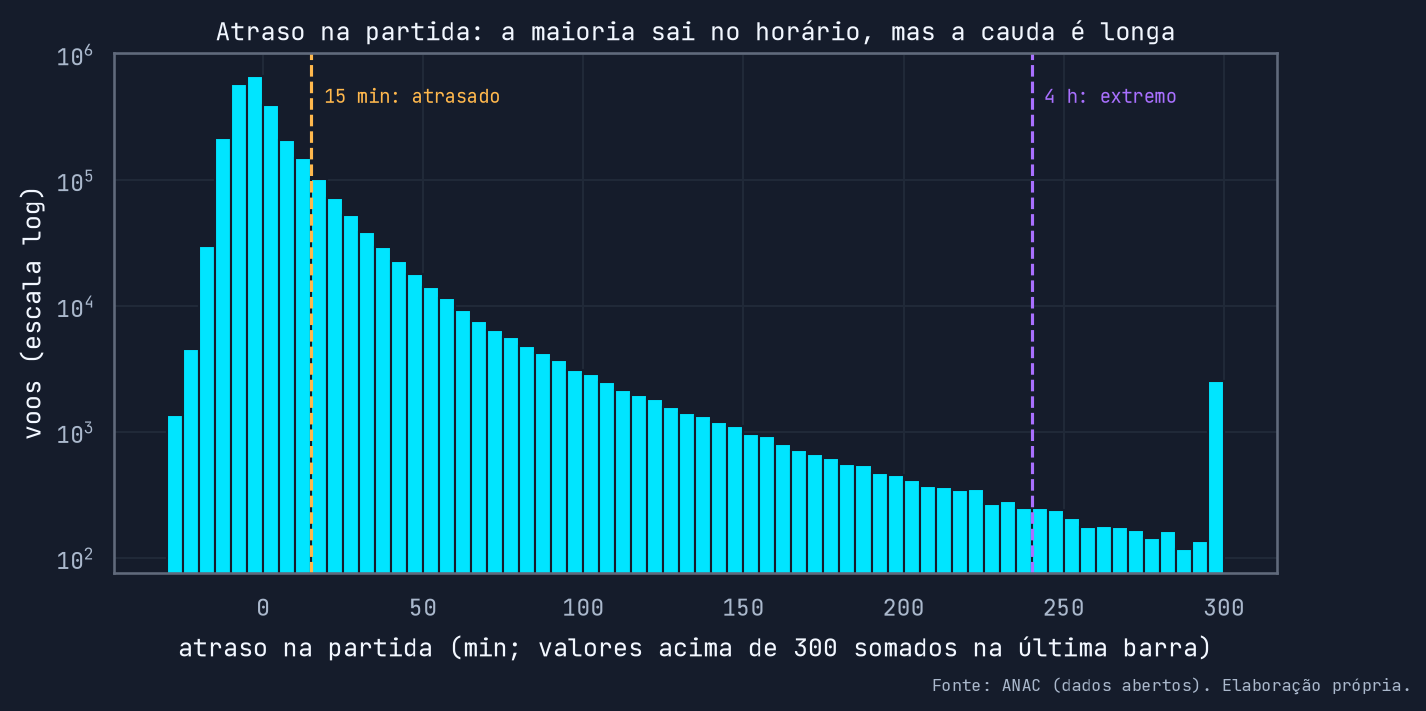

In [19]:
atrasos = q('''
    SELECT atraso_partida_min FROM fato_voo JOIN dim_empresa USING (empresa_icao)
    WHERE atraso_partida_min IS NOT NULL
''')['atraso_partida_min']
extremos = (atrasos > LIMIAR_OUTLIER).sum()
print(f'voos com horário válido: {br(len(atrasos), 0)} | mediana: {atrasos.median():.0f} min | '
      f'acima de {LIMIAR_ATRASO} min: {br(100 * (atrasos > LIMIAR_ATRASO).mean())} % | '
      f'acima de {LIMIAR_OUTLIER} min: {br(extremos, 0)} ({br(100 * extremos / len(atrasos), 2)} %)')

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(atrasos.clip(-30, 300), bins=np.arange(-30, 302, 5), color=tema.CIANO)
ax.set_yscale('log')
ax.axvline(LIMIAR_ATRASO, color=tema.AMBAR, ls='--', lw=1.5)
ax.axvline(LIMIAR_OUTLIER, color=tema.ROXO, ls='--', lw=1.5)
ax.text(LIMIAR_ATRASO + 4, ax.get_ylim()[1] * 0.4, '15 min: atrasado', color=tema.AMBAR, fontsize=9)
ax.text(LIMIAR_OUTLIER + 4, ax.get_ylim()[1] * 0.4, '4 h: extremo', color=tema.ROXO, fontsize=9)
ax.set(title='Atraso na partida: a maioria sai no horário, mas a cauda é longa',
       xlabel='atraso na partida (min; valores acima de 300 somados na última barra)', ylabel='voos (escala log)')
fonte(fig)
plt.show()

⚠️ **O que observar:** a escala logarítmica é o que deixa a cauda visível; em escala linear o gráfico seria uma única barra perto de zero. Os atrasos extremos são poucos, mas não são erros: depois da correção da virada de dia, são voos que de fato saíram horas depois. Eles ficam na análise, e os KPIs usam proporções (acima de 15 min), que não são distorcidas por valores extremos como a média seria.

### 5.3 Evolução mensal

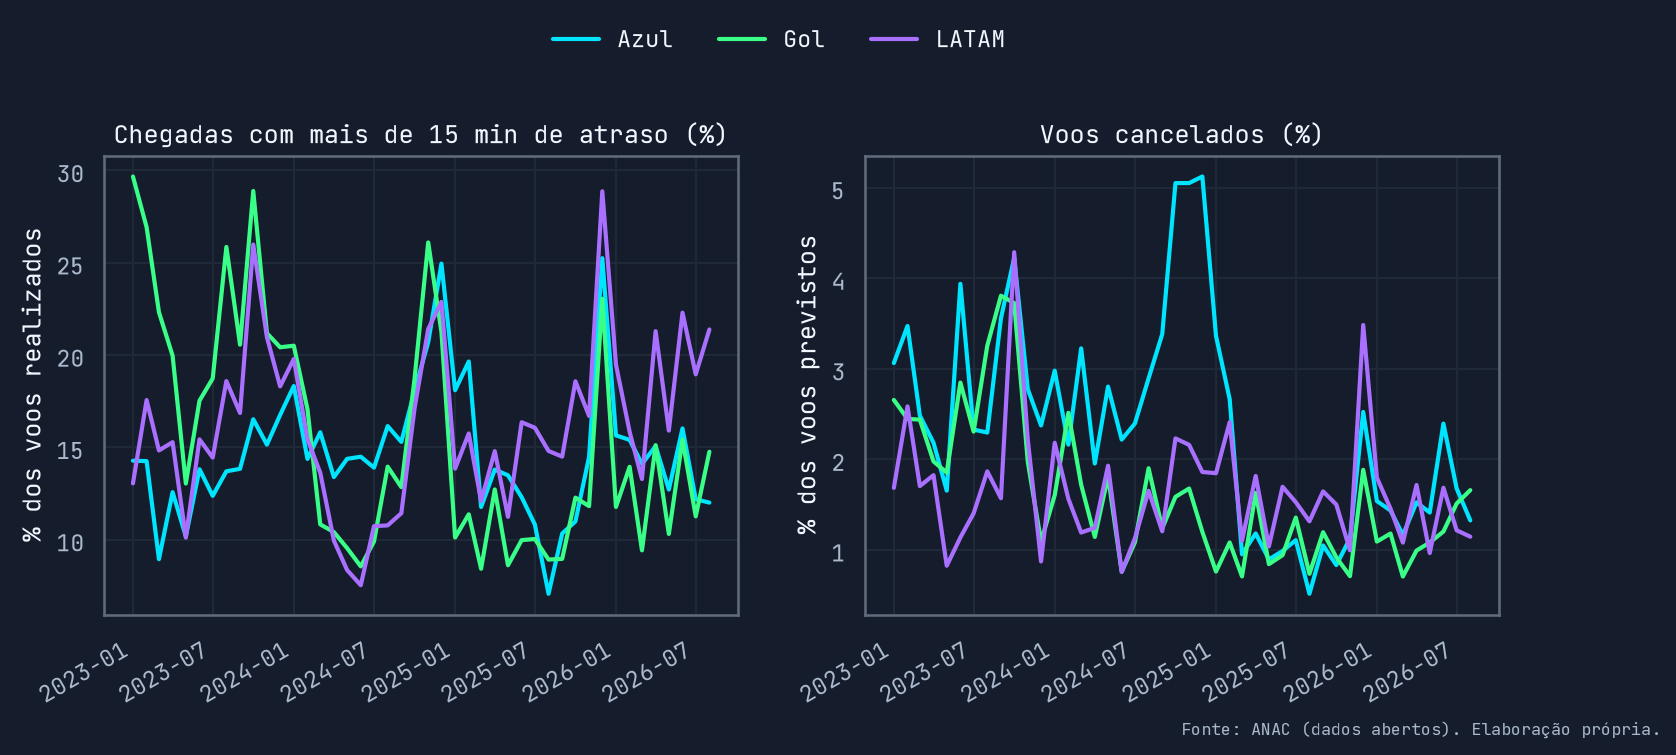

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
for emp in EMPRESAS:
    d = painel_completo[painel_completo.empresa == emp]
    ax1.plot(d.ano_mes, d.pct_atraso15_chegada, color=CORES[emp], lw=2, label=emp)
    ax2.plot(d.ano_mes, d.pct_cancelados, color=CORES[emp], lw=2, label=emp)
ax1.set(title='Chegadas com mais de 15 min de atraso (%)', ylabel='% dos voos realizados')
ax2.set(title='Voos cancelados (%)', ylabel='% dos voos previstos')
fig.legend(*ax1.get_legend_handles_labels(), loc='lower center', bbox_to_anchor=(0.5, 1.0), ncols=3, frameon=False)
fig.autofmt_xdate()
fonte(fig)
plt.show()

## 6. Sazonalidade: mês, dia da semana e hora

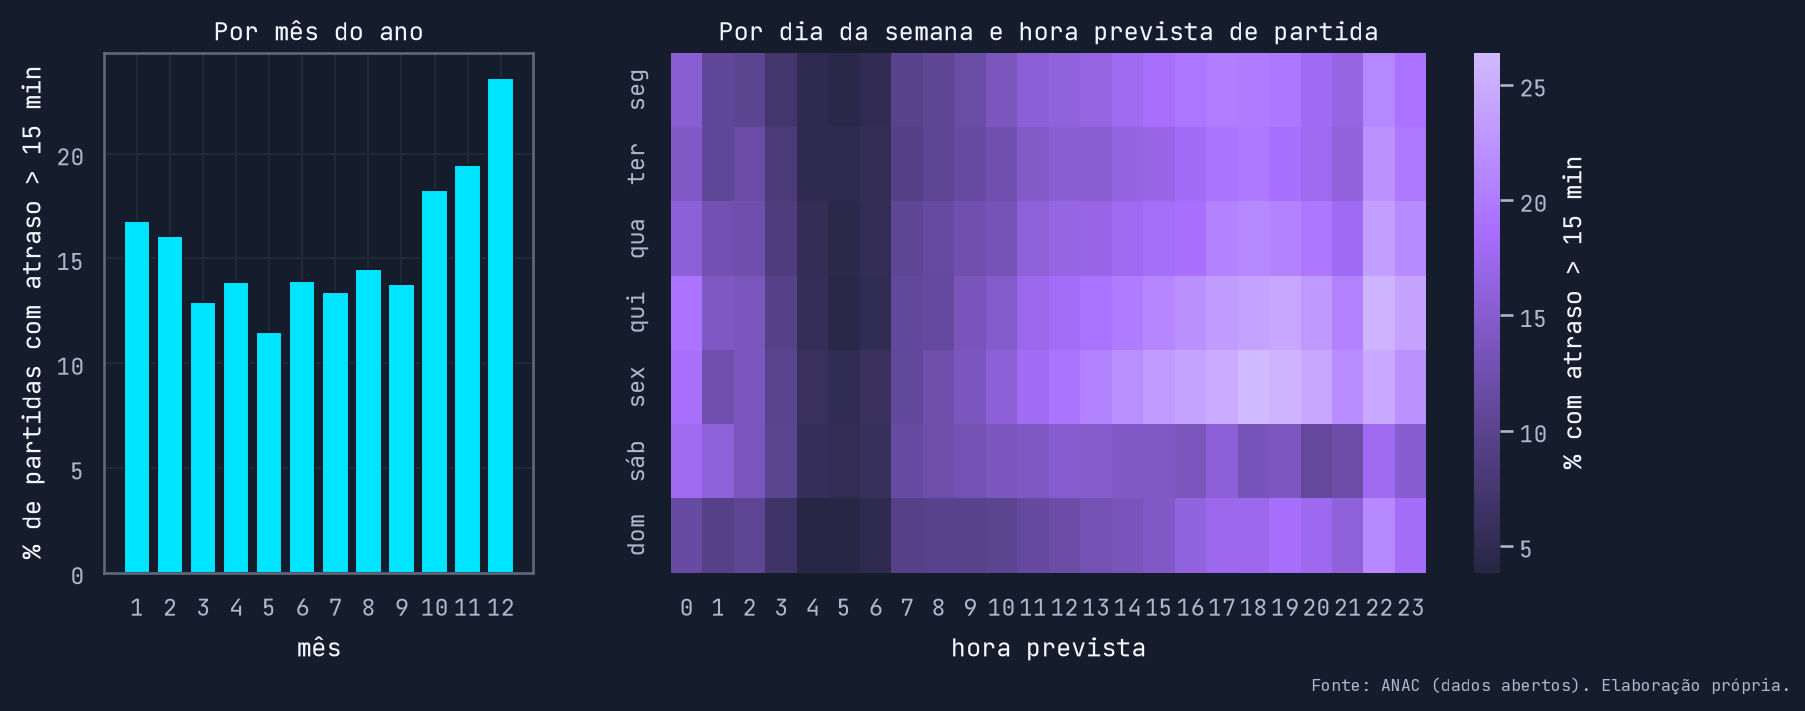

mês com mais atraso: 12 (23,6 %); hora mais crítica: 22h (22,4 %); mais tranquila: 5h (4,6 %)


In [21]:
por_mes = q('''
    SELECT month(data_id) AS mes, 100.0 * avg((atraso_partida_min > 15)::INT) AS pct_atraso
    FROM fato_voo JOIN dim_empresa USING (empresa_icao) GROUP BY ALL ORDER BY mes
''')
hora_dia = q('''
    SELECT hora_prevista, isodow(data_id) AS dia_semana, 100.0 * avg((atraso_partida_min > 15)::INT) AS pct_atraso
    FROM fato_voo JOIN dim_empresa USING (empresa_icao)
    WHERE atraso_partida_min IS NOT NULL GROUP BY ALL
''').pivot(index='dia_semana', columns='hora_prevista', values='pct_atraso')
hora_dia.index = ['seg', 'ter', 'qua', 'qui', 'sex', 'sáb', 'dom']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [1, 2.2]})
ax1.bar(por_mes.mes, por_mes.pct_atraso, color=tema.CIANO)
ax1.set(title='Por mês do ano', xlabel='mês', ylabel='% de partidas com atraso > 15 min', xticks=range(1, 13))
sns.heatmap(hora_dia, ax=ax2, cmap='ds_seq', cbar_kws={'label': '% com atraso > 15 min'})
ax2.set(title='Por dia da semana e hora prevista de partida', xlabel='hora prevista', ylabel='')
fonte(fig)
plt.show()
mes_pico = por_mes.loc[por_mes.pct_atraso.idxmax()]
hora_pico = hora_dia.mean().idxmax()
print(f'mês com mais atraso: {int(mes_pico.mes)} ({br(mes_pico.pct_atraso)} %); '
      f'hora mais crítica: {hora_pico}h ({br(hora_dia.mean().max())} %); '
      f'mais tranquila: {hora_dia.mean().idxmin()}h ({br(hora_dia.mean().min())} %)')

⚠️ **O que observar:** dezembro é o pior mês e maio o melhor; quinta e sexta à tarde e à noite são os piores horários da semana. O atraso se acumula ao longo do dia. O avião que atrasa de manhã leva o atraso para as etapas seguintes, e o primeiro voo do dia é o mais pontual. Isso é informação conhecida na hora de montar a malha, e o modelo da seção 10 a usa.

## 7. Reclamações: taxa por passageiro, funil e conversão

### 7.1 Reclamações por 100 mil passageiros pagos

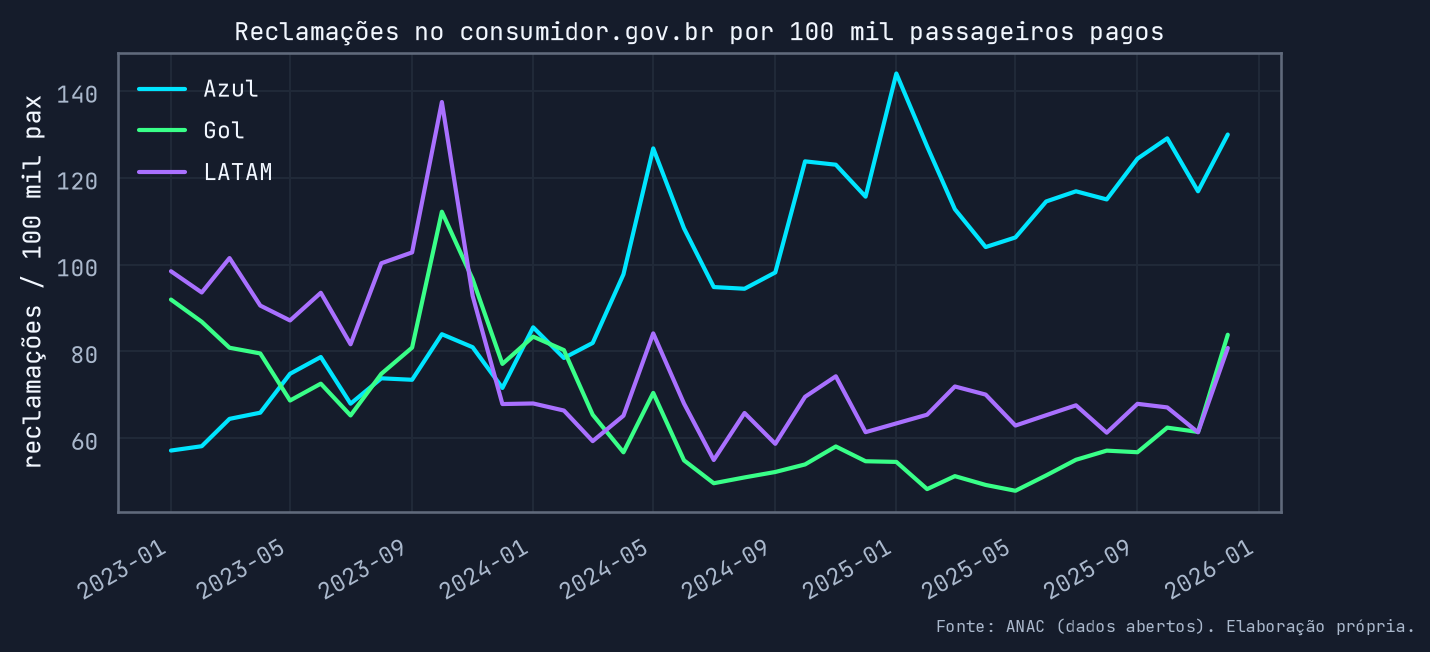

,empresa,2023,2024,2025
0,Azul,"71,0","102,8","120,0"
1,Gol,"82,4","60,6","57,2"
2,LATAM,"95,5","66,1","67,1"


In [22]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for emp in EMPRESAS:
    d = painel[painel.empresa == emp]
    ax.plot(d.ano_mes, d.reclamacoes_100k, color=CORES[emp], lw=2, label=emp)
ax.set(title='Reclamações no consumidor.gov.br por 100 mil passageiros pagos', ylabel='reclamações / 100 mil pax')
ax.legend(frameon=False)
fig.autofmt_xdate()
fonte(fig)
plt.show()
taxa_ano = painel.groupby(['empresa', 'ano']).apply(
    lambda d: 1e5 * d.reclamacoes.sum() / d.passageiros_pagos.sum(), include_groups=False).unstack()
tabela(taxa_ano.reset_index().rename_axis(None, axis=1))

⚠️ **O que observar:** a taxa de cada companhia muda de patamar de um ano para o outro, mais do que a pontualidade dela muda. Isso já sugere que algo além do atraso move as reclamações, e é o que a regressão da seção 9 precisa controlar.

### 7.2 Funil da reclamação

**O que faz:** acompanha a reclamação da abertura à avaliação: aberta → respondida pela companhia → avaliada pelo consumidor → resolvida.

In [23]:
funil = painel.groupby('empresa')[['reclamacoes', 'respondidas', 'avaliadas', 'resolvidas']].sum()
funil_pct = 100 * funil.div(funil['reclamacoes'], axis=0)
funil_pct['resolvidas_entre_avaliadas'] = 100 * funil['resolvidas'] / funil['avaliadas']
tempo = q('''
    SELECT e.empresa, avg(tempo_resposta_dias) AS tempo_medio_dias, median(tempo_resposta_dias) AS tempo_mediano_dias
    FROM fato_reclamacao AS r JOIN dim_empresa AS e ON r.nome_fantasia = e.nome_fantasia_consumidor
    GROUP BY ALL
''').set_index('empresa')
tabela(funil_pct.join(tempo).reset_index())

,empresa,reclamacoes,respondidas,avaliadas,resolvidas,resolvidas_entre_avaliadas,tempo_medio_dias,tempo_mediano_dias
0,Azul,"100,0","100,0","52,7","42,4","80,5","6,6","7,0"
1,Gol,"100,0","99,9","52,8","39,0","73,9","5,5","6,0"
2,LATAM,"100,0","99,9","57,5","44,1","76,8","3,6","2,0"


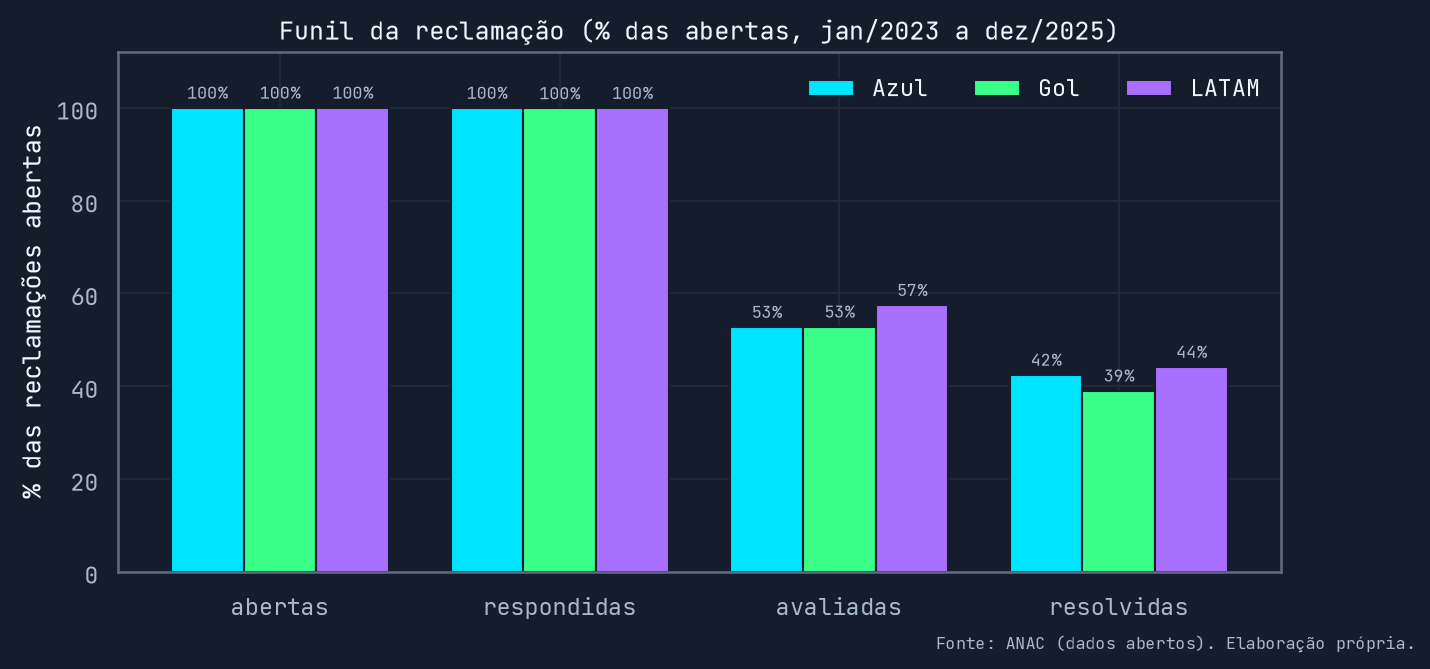

In [24]:
etapas = ['reclamacoes', 'respondidas', 'avaliadas', 'resolvidas']
rotulos = ['abertas', 'respondidas', 'avaliadas', 'resolvidas']
fig, ax = plt.subplots(figsize=(10, 4.5))
largura = 0.26
for k, emp in enumerate(EMPRESAS):
    valores = funil_pct.loc[emp, etapas].to_numpy()
    barras = ax.bar(np.arange(4) + (k - 1) * largura, valores, largura, color=CORES[emp], label=emp)
    ax.bar_label(barras, labels=[f'{br(v, 0)}%' for v in valores], fontsize=8, color=tema.TEXTO_2, padding=2)
ax.set_xticks(range(4), rotulos)
ax.set(title='Funil da reclamação (% das abertas, jan/2023 a dez/2025)', ylabel='% das reclamações abertas', ylim=(0, 112))
ax.legend(frameon=False, ncols=3, loc='upper right')
fonte(fig)
plt.show()

⚠️ **O que observar:** responder não é resolver. As três respondem praticamente tudo; a diferença entre elas aparece na avaliação do consumidor.

### 7.3 Conversão de problema operacional em reclamação não resolvida

**O que faz:** responde à terceira pergunta. Para cada companhia, divide as reclamações **operacionais** que terminaram **não resolvidas** pelo número de voos com problema (cancelados ou com chegada mais de 15 minutos atrasada), por mil voos. O intervalo de 95 % trata a contagem de reclamações como Poisson.

In [25]:
conv = painel.groupby('empresa')[['voos_cancelados', 'voos_atraso15_chegada', 'nao_resolvidas_operacionais',
                                  'reclamacoes_operacionais', 'nao_resolvidas', 'passageiros_domesticos']].sum()
conv['voos_com_problema'] = conv.voos_cancelados + conv.voos_atraso15_chegada
# intervalo exato de Poisson para a contagem de reclamações não resolvidas
conv['ic_inf'] = stats.chi2.ppf(0.025, 2 * conv.nao_resolvidas_operacionais) / 2
conv['ic_sup'] = stats.chi2.ppf(0.975, 2 * (conv.nao_resolvidas_operacionais + 1)) / 2
for c in ['nao_resolvidas_operacionais', 'ic_inf', 'ic_sup']:
    conv[c + '_por_mil'] = 1000 * conv[c] / conv.voos_com_problema
conv['pct_nao_resolvidas_entre_operacionais'] = 100 * conv.nao_resolvidas_operacionais / conv.reclamacoes_operacionais
conv['operacionais_por_mil_problemas'] = 1000 * conv.reclamacoes_operacionais / conv.voos_com_problema
conv['pct_cancelados_entre_problemas'] = 100 * conv.voos_cancelados / conv.voos_com_problema
conv.to_csv(PASTA_AGREGADOS / 'conversao_empresa.csv', float_format='%.4f')
tabela(conv[['voos_com_problema', 'pct_cancelados_entre_problemas', 'reclamacoes_operacionais', 'operacionais_por_mil_problemas',
             'pct_nao_resolvidas_entre_operacionais', 'nao_resolvidas_operacionais',
             'nao_resolvidas_operacionais_por_mil', 'ic_inf_por_mil', 'ic_sup_por_mil']].reset_index(), 1)

,empresa,voos_com_problema,pct_cancelados_entre_problemas,reclamacoes_operacionais,operacionais_por_mil_problemas,pct_nao_resolvidas_entre_operacionais,nao_resolvidas_operacionais,nao_resolvidas_operacionais_por_mil,ic_inf_por_mil,ic_sup_por_mil
0,Azul,145.568,"15,0",21.524,"147,9","13,4",2.884,"19,8","19,1","20,5"
1,Gol,110.665,"9,7",12.887,"116,5","15,9",2.043,"18,5","17,7","19,3"
2,LATAM,127.619,"9,9",14.776,"115,8","13,4",1.985,"15,6","14,9","16,3"


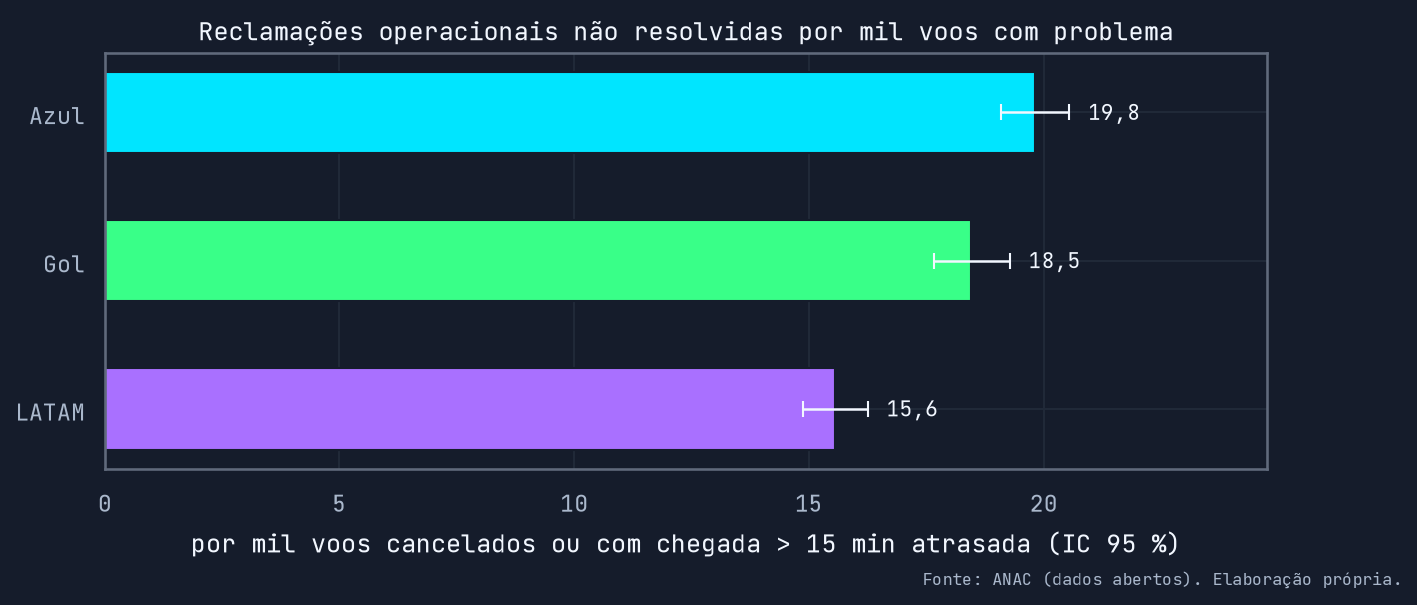

In [26]:
ordem = conv.sort_values('nao_resolvidas_operacionais_por_mil').index
fig, ax = plt.subplots(figsize=(10, 3.6))
y = np.arange(len(ordem))
v = conv.loc[ordem, 'nao_resolvidas_operacionais_por_mil']
ax.barh(y, v, color=[CORES[e] for e in ordem], height=0.55)
ax.errorbar(v, y, xerr=[v - conv.loc[ordem, 'ic_inf_por_mil'], conv.loc[ordem, 'ic_sup_por_mil'] - v],
            fmt='none', ecolor=tema.TEXTO, capsize=4, lw=1.2)
for yi, vi, sup in zip(y, v, conv.loc[ordem, 'ic_sup_por_mil']):
    ax.text(sup + 0.4, yi, br(vi), va='center', color=tema.TEXTO, fontsize=10)
ax.set_yticks(y, ordem)
ax.set(title='Reclamações operacionais não resolvidas por mil voos com problema',
       xlabel='por mil voos cancelados ou com chegada > 15 min atrasada (IC 95 %)', xlim=(0, v.max() * 1.25))
fonte(fig)
plt.show()

⚠️ **O que observar**
- A conversão tem duas partes: quantas reclamações operacionais cada voo com problema gera, e que fração delas termina não resolvida. A tabela mostra as duas.
- O denominador é o voo, não o passageiro. A Azul opera aviões menores (menos passageiros por voo), o que puxaria a taxa dela **para baixo**; mesmo assim ela converte mais.

## 8. Pontualidade entre companhias: testes de proporções

**O que faz:** testa se a proporção de chegadas com mais de 15 minutos de atraso difere entre as companhias (qui-quadrado de independência) e compara os pares (teste z de duas proporções, com correção de Bonferroni), com o tamanho de efeito *h* de Cohen.

**Quando usar:** sempre que a pergunta é "esta taxa é diferente daquela?". Com milhões de voos, o ponto principal é o tamanho de efeito: quase qualquer diferença dá p-valor minúsculo.

In [27]:
cont = q('''
    SELECT e.empresa, count(*) FILTER (WHERE atraso_chegada_min > 15) AS atrasados,
           count(*) FILTER (WHERE atraso_chegada_min <= 15) AS no_horario
    FROM fato_voo JOIN dim_empresa AS e USING (empresa_icao)
    WHERE atraso_chegada_min IS NOT NULL GROUP BY ALL ORDER BY e.empresa
''').set_index('empresa')
qui2, p_qui2, gl, _ = stats.chi2_contingency(cont)
n_total = cont.to_numpy().sum()
v_cramer = np.sqrt(qui2 / (n_total * (min(cont.shape) - 1)))
print(f'qui-quadrado = {br(qui2, 0)}, gl = {gl}, p = {p_qui2:.1e}, V de Cramér = {v_cramer:.3f}')

pares = []
for a, b in [('Azul', 'Gol'), ('Azul', 'LATAM'), ('Gol', 'LATAM')]:
    x = cont.loc[[a, b], 'atrasados'].to_numpy()
    n = cont.loc[[a, b]].sum(axis=1).to_numpy()
    z, p = proportions_ztest(x, n)
    pa, pb = x / n
    erro = np.sqrt(pa * (1 - pa) / n[0] + pb * (1 - pb) / n[1])
    h = 2 * np.arcsin(np.sqrt(pa)) - 2 * np.arcsin(np.sqrt(pb))
    pares.append({'par': f'{a} − {b}', 'diferenca_pp': 100 * (pa - pb),
                  'ic95_inf_pp': 100 * (pa - pb - 1.96 * erro), 'ic95_sup_pp': 100 * (pa - pb + 1.96 * erro),
                  'p_bonferroni': min(1, 3 * p), 'h_de_cohen': h})
pares = pd.DataFrame(pares)
tabela(pares.assign(p_bonferroni=pares.p_bonferroni.map(lambda p: f'{p:.1e}')), 3)

qui-quadrado = 999, gl = 2, p = 1.3e-217, V de Cramér = 0.019


,par,diferenca_pp,ic95_inf_pp,ic95_sup_pp,p_bonferroni,h_de_cohen
0,Azul − Gol,"-0,858","-0,964","-0,752",1.5e-56,"-0,024"
1,Azul − LATAM,"-1,645","-1,747","-1,542",2.0e-218,"-0,046"
2,Gol − LATAM,"-0,787","-0,897","-0,676",1.8e-43,"-0,022"


⚠️ **O que observar:** todas as diferenças são "estatisticamente significativas", e todas são **pequenas**: |*h*| abaixo de 0,05, quando 0,2 é o limite convencional de um efeito pequeno, e V de Cramér perto de zero. No agregado do período, as três companhias têm praticamente a mesma pontualidade; o que muda é a trajetória de cada uma ao longo do tempo (seção 5.3).

## 9. Regressão: reclamações × atraso e cancelamento

### 9.1 A relação nos dados

**O que faz:** cada ponto é uma companhia em um mês (108 pontos: 3 companhias × 36 meses).

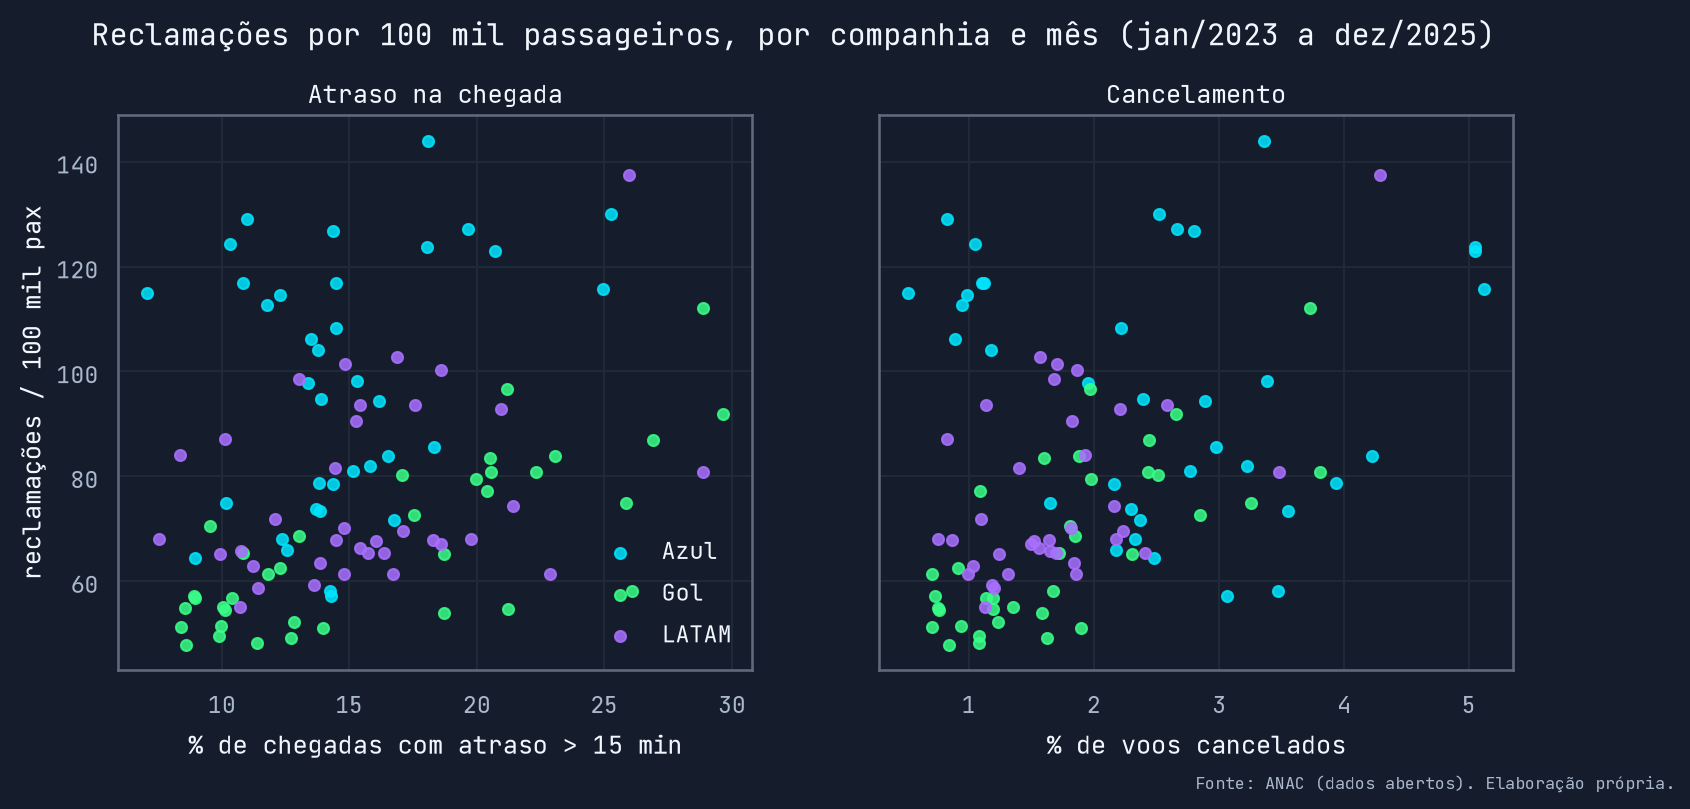

correlação (Pearson) com reclamações/100k: atraso = 0.30, cancelamento = 0.38


In [28]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for emp in EMPRESAS:
    d = painel[painel.empresa == emp]
    ax1.scatter(d.pct_atraso15_chegada, d.reclamacoes_100k, color=CORES[emp], s=28, alpha=0.85, label=emp)
    ax2.scatter(d.pct_cancelados, d.reclamacoes_100k, color=CORES[emp], s=28, alpha=0.85, label=emp)
ax1.set(title='Atraso na chegada', xlabel='% de chegadas com atraso > 15 min', ylabel='reclamações / 100 mil pax')
ax2.set(title='Cancelamento', xlabel='% de voos cancelados')
ax1.legend(frameon=False)
fig.suptitle('Reclamações por 100 mil passageiros, por companhia e mês (jan/2023 a dez/2025)', y=1.02)
fonte(fig)
plt.show()
print(f'correlação (Pearson) com reclamações/100k: atraso = {painel.pct_atraso15_chegada.corr(painel.reclamacoes_100k):.2f}, '
      f'cancelamento = {painel.pct_cancelados.corr(painel.reclamacoes_100k):.2f}')

### 9.2 Três modelos, do mais ingênuo ao mais controlado

**O que faz:** estima quantas reclamações por 100 mil passageiros acompanham cada ponto percentual de atraso e de cancelamento.

| Modelo | Controles | O que a variação usada representa |
|---|---|---|
| M1 | nenhum | diferenças entre companhias e entre meses, misturadas |
| M2 | companhia + mês do calendário + tendência linear | variação dentro da companhia, já descontada a sazonalidade comum |
| M3 (principal) | companhia × ano + mês do calendário | variação mês a mês dentro do mesmo ano da mesma companhia |

O M3 absorve choques que duram o ano inteiro numa companhia (uma recuperação judicial, uma mudança na política de reembolso, uma campanha de atendimento), que movem as reclamações sem passar pela operação.

Os resíduos de meses vizinhos da mesma companhia são correlacionados (Durbin-Watson perto de 1, seção 9.3), então os erros-padrão são do tipo HAC em painel (Newey-West dentro de cada companhia, até 3 meses de defasagem), que não subestimam a incerteza como os erros comuns fariam.

**Teste placebo:** o mesmo modelo para as reclamações de **cobrança**, que não deveriam responder a atraso ou cancelamento no mesmo mês. Se responderem, o modelo está captando um choque comum, não o efeito da operação.

In [29]:
formulas = {
    'M1': '{y} ~ pct_atraso15_chegada + pct_cancelados',
    'M2': '{y} ~ pct_atraso15_chegada + pct_cancelados + C(empresa) + C(mes) + I(ano * 12 + mes)',
    'M3': '{y} ~ pct_atraso15_chegada + pct_cancelados + C(empresa):C(ano) + C(mes)',
}
desfechos = {'reclamacoes_100k': 'todas', 'reclamacoes_operacionais_100k': 'operacionais',
             'reclamacoes_cobranca_100k': 'cobrança (placebo)'}
painel = painel.sort_values(['empresa', 'ano_mes']).reset_index(drop=True)   # o HAC em painel exige a ordem
grupos = painel['empresa'].astype('category').cat.codes.to_numpy()
linhas, modelos = [], {}
for y, nome_y in desfechos.items():
    for nome_m, f in formulas.items():
        m = smf.ols(f.format(y=y), painel).fit(cov_type='hac-panel', cov_kwds={'groups': grupos, 'maxlags': 3})
        modelos[(y, nome_m)] = m
        ic = m.conf_int()
        for x, nome_x in [('pct_atraso15_chegada', 'atraso > 15 min (+1 p.p.)'), ('pct_cancelados', 'cancelamento (+1 p.p.)')]:
            linhas.append({'reclamações': nome_y, 'modelo': nome_m, 'variável': nome_x, 'coef': m.params[x],
                           'ic95_inf': ic.loc[x, 0], 'ic95_sup': ic.loc[x, 1], 'p': m.pvalues[x],
                           'efeito_%_da_media': 100 * m.params[x] / painel[y].mean(), 'r2': m.rsquared})
coefs = pd.DataFrame(linhas)
coefs.to_csv(PASTA_AGREGADOS / 'regressao_coeficientes.csv', index=False, float_format='%.4f')
tabela(coefs.assign(p=coefs.p.map(lambda p: f'{p:.3f}')), 2)

,reclamações,modelo,variável,coef,ic95_inf,ic95_sup,p,efeito_%_da_media,r2
0,todas,M1,atraso > 15 min (+1 p.p.),"0,60","-0,53","1,72",0.297,"0,75","0,16"
1,todas,M1,cancelamento (+1 p.p.),"6,99","-0,31","14,29",0.061,"8,71","0,16"
2,todas,M2,atraso > 15 min (+1 p.p.),"2,81","1,49","4,13",0.000,"3,50","0,52"
3,todas,M2,cancelamento (+1 p.p.),"-3,34","-11,42","4,74",0.418,"-4,16","0,52"
4,todas,M3,atraso > 15 min (+1 p.p.),"0,41","-0,55","1,37",0.404,"0,51","0,87"
5,todas,M3,cancelamento (+1 p.p.),"7,01","2,98","11,05",0.001,"8,74","0,87"
6,operacionais,M1,atraso > 15 min (+1 p.p.),"0,06","-0,24","0,36",0.682,"0,37","0,27"
7,operacionais,M1,cancelamento (+1 p.p.),"3,62","1,43","5,80",0.001,"21,47","0,27"
8,operacionais,M2,atraso > 15 min (+1 p.p.),"0,69","0,39","0,99",0.000,"4,11","0,82"
9,operacionais,M2,cancelamento (+1 p.p.),"1,37","0,17","2,58",0.026,"8,15","0,82"


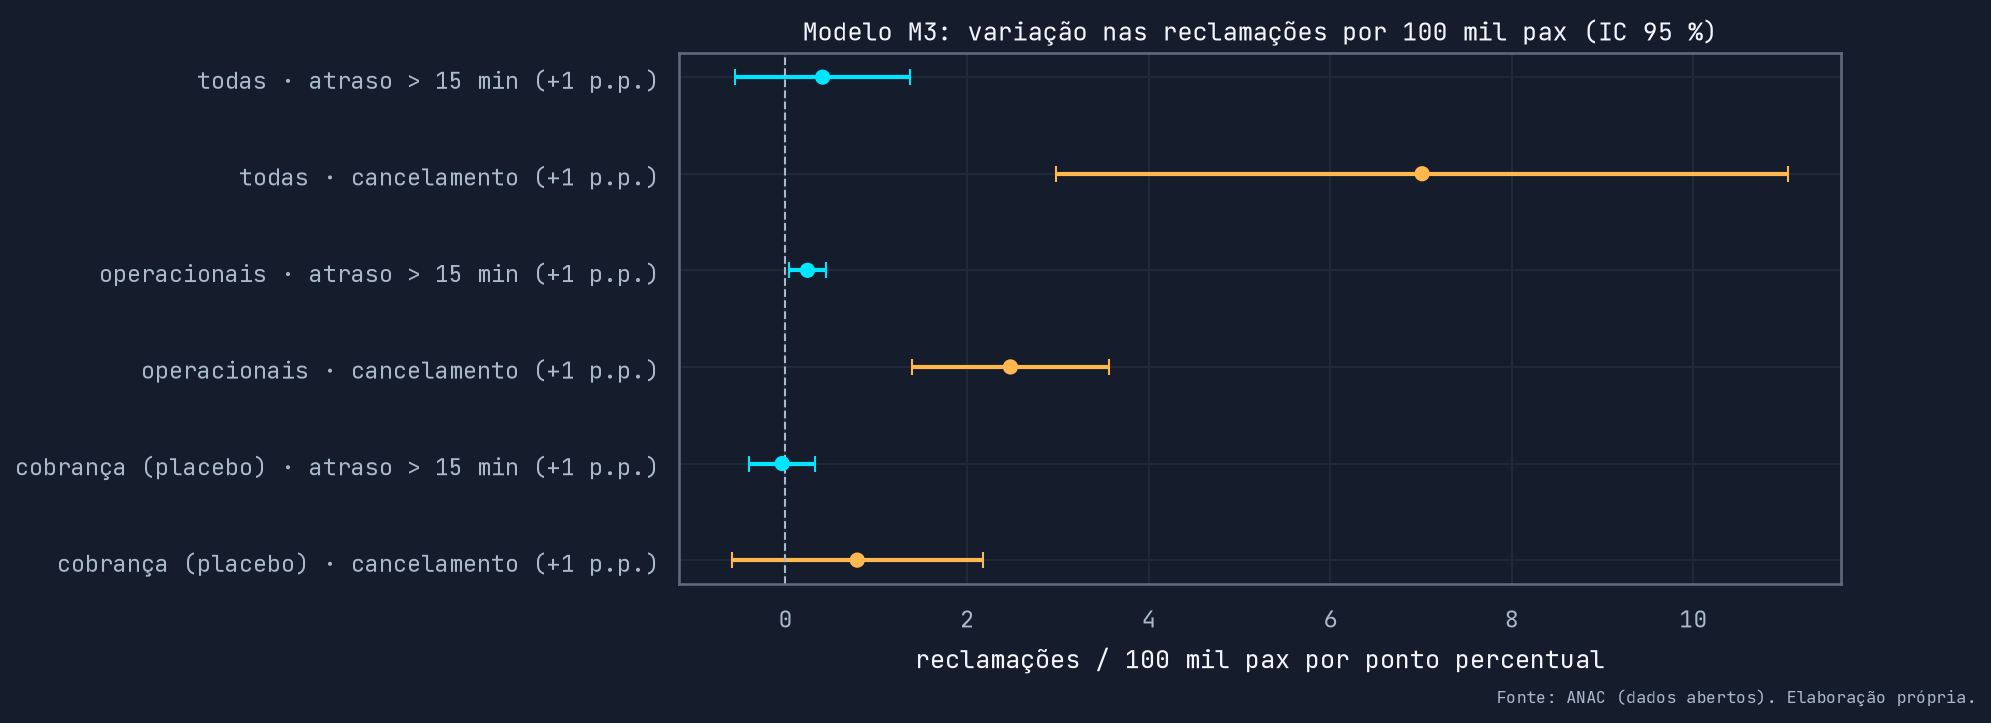

In [30]:
m3 = coefs[coefs.modelo == 'M3']
fig, ax = plt.subplots(figsize=(10, 4.6))
y = np.arange(len(m3))[::-1]
cores = [tema.CIANO if 'atraso' in v else tema.AMBAR for v in m3['variável']]
for yi, (_, r), cor in zip(y, m3.iterrows(), cores):
    ax.errorbar(r.coef, yi, xerr=[[r.coef - r.ic95_inf], [r.ic95_sup - r.coef]], fmt='none', ecolor=cor, capsize=4, lw=2)
ax.scatter(m3.coef, y, color=cores, s=40, zorder=3)
ax.axvline(0, color=tema.TEXTO_2, lw=1, ls='--')
ax.set_yticks(y, [f"{r['reclamações']} · {r['variável']}" for _, r in m3.iterrows()])
ax.set(title='Modelo M3: variação nas reclamações por 100 mil pax (IC 95 %)',
       xlabel='reclamações / 100 mil pax por ponto percentual')
fonte(fig)
plt.show()

### 9.3 Quanto do vaivém das reclamações a operação explica

**O que faz:** compara o R² do modelo M3 com e sem as duas variáveis operacionais. A diferença é o quanto atraso e cancelamento acrescentam depois que os efeitos de companhia × ano e de mês do calendário já entraram.

In [31]:
so_controles = smf.ols('reclamacoes_100k ~ C(empresa):C(ano) + C(mes)', painel).fit()
completo = modelos[('reclamacoes_100k', 'M3')]
r2_controles, r2_completo = so_controles.rsquared, completo.rsquared
r2_parcial = (r2_completo - r2_controles) / (1 - r2_controles)
print(f'R² só com companhia × ano e mês: {br(r2_controles, 3)} | com atraso e cancelamento: {br(r2_completo, 3)} | '
      f'R² parcial da operação: {br(r2_parcial, 3)}')
print(f'Durbin-Watson dos resíduos do M3: {br(float(np.sum(np.diff(completo.resid) ** 2) / np.sum(completo.resid ** 2)), 2)}')

R² só com companhia × ano e mês: 0,815 | com atraso e cancelamento: 0,867 | R² parcial da operação: 0,285
Durbin-Watson dos resíduos do M3: 1,00


⚠️ **O que observar**
- **Falácia ecológica:** a regressão é no nível companhia × mês. Ela diz que meses com mais cancelamentos têm mais reclamações por passageiro; não diz que um passageiro específico reclamou por causa de um cancelamento específico.
- **Associação, não causa:** o modelo M3 e o placebo afastam as explicações mais óbvias, mas não todas (por exemplo, um mês com problema no sistema de vendas que também atrapalhe a operação).
- O consumidor.gov.br só tem quem decidiu reclamar ali. Uma mudança na divulgação da plataforma muda as reclamações sem mudar a operação; o efeito companhia × ano absorve parte disso.

## 10. Machine Learning: risco de atraso na partida maior que 30 minutos

**O que faz:** estima, para cada voo da malha, a probabilidade de partir mais de 30 minutos atrasado, usando **só o que se sabe quando a malha é montada**.

**Quando usar:** para priorizar recursos antes do dia do voo: tripulação e aeronave reserva, reforço de equipe em solo, ajuste de horários com risco alto de forma repetida.

### 10.1 Variáveis e ausência de vazamento

| Variável | Por que é conhecida antes do voo |
|---|---|
| companhia, origem, destino | estão na malha |
| hora prevista, dia da semana, mês | estão na malha |
| duração prevista (chegada prevista − partida prevista) | está na malha |
| partidas previstas no aeródromo de origem na mesma hora; chegadas previstas no destino na mesma hora | contadas na própria malha (congestionamento programado) |

Ficam de fora, de propósito: horário real, atraso, situação do voo (realizado ou cancelado) e qualquer agregado calculado com dados do período de teste.

In [32]:
dados_ml = q('''
    WITH programados AS (
        SELECT *, date_trunc('hour', partida_prevista) AS hora_partida, date_trunc('hour', chegada_prevista) AS hora_chegada
        FROM fato_voo WHERE situacao IN ('REALIZADO', 'CANCELADO')
    ),
    partidas AS (SELECT origem_icao, hora_partida, count(*) AS partidas_origem_hora FROM programados GROUP BY ALL),
    chegadas AS (SELECT destino_icao, hora_chegada, count(*) AS chegadas_destino_hora FROM programados GROUP BY ALL)
    SELECT e.empresa, p.origem_icao AS origem, p.destino_icao AS destino, p.hora_prevista,
           isodow(p.data_id) AS dia_semana, month(p.data_id) AS mes, p.data_id,
           date_diff('minute', p.partida_prevista, p.chegada_prevista) AS duracao_prevista_min,
           partidas_origem_hora, chegadas_destino_hora,
           (p.atraso_partida_min > 30)::INT AS alvo
    FROM programados AS p
    JOIN dim_empresa AS e USING (empresa_icao)
    LEFT JOIN partidas USING (origem_icao, hora_partida)
    LEFT JOIN chegadas USING (destino_icao, hora_chegada)
    WHERE p.horario_real_valido            -- o alvo só existe para voos realizados com horário válido
''')
VARIAVEIS = ['empresa', 'origem', 'destino', 'hora_prevista', 'dia_semana', 'mes', 'duracao_prevista_min',
             'partidas_origem_hora', 'chegadas_destino_hora']
PROIBIDAS = {'partida_real', 'chegada_real', 'atraso_partida_min', 'atraso_chegada_min', 'situacao', 'alvo', 'data_id'}
assert not PROIBIDAS & set(VARIAVEIS), 'vazamento: variável conhecida só depois do voo'
print(f'{br(len(dados_ml), 0)} voos; taxa de atraso > 30 min: {br(100 * dados_ml.alvo.mean())} %')

2.699.016 voos; taxa de atraso > 30 min: 7,5 %


### 10.2 Divisão temporal

Os dados são divididos **por data, sem embaralhar**: o modelo é sempre avaliado em meses posteriores aos que viu no treino, como acontece na prática.

| Conjunto | Período | Uso |
|---|---|---|
| treino | jan/2023 a jun/2025 | ajustar os candidatos |
| validação | jul a dez/2025 | escolher a configuração |
| teste | jan a ago/2026 | medir o desempenho final, uma única vez |

As categorias (aeródromos) são definidas só com o treino; aeródromo novo no teste vira `OUTROS`.

In [33]:
def preparar(df, categorias=None):
    df = df.copy()
    if categorias is None:
        categorias = {c: sorted(set(df[c].value_counts().index[:200]) | {'OUTROS'}) for c in ['empresa', 'origem', 'destino']}
    for c, valores in categorias.items():
        df[c] = df[c].where(df[c].isin(valores), 'OUTROS').astype(pd.CategoricalDtype(valores))
    return df, categorias


datas = pd.to_datetime(dados_ml.data_id)
treino_cru = dados_ml[datas < CORTE_VALIDACAO]
valid_cru = dados_ml[(datas >= CORTE_VALIDACAO) & (datas < CORTE_TESTE)]
treino, cats = preparar(treino_cru)
valid, _ = preparar(valid_cru, cats)

candidatos = {'raso (31 folhas, taxa 0,1)': dict(max_leaf_nodes=31, learning_rate=0.1, max_iter=200),
              'profundo (63 folhas, taxa 0,1)': dict(max_leaf_nodes=63, learning_rate=0.1, max_iter=300)}
resultado_validacao = {}
for nome, params in candidatos.items():
    m = HistGradientBoostingClassifier(categorical_features='from_dtype', early_stopping=False,
                                       random_state=SEMENTE, **params).fit(treino[VARIAVEIS], treino.alvo)
    resultado_validacao[nome] = average_precision_score(valid.alvo, m.predict_proba(valid[VARIAVEIS])[:, 1])
escolhido = max(resultado_validacao, key=resultado_validacao.get)
print({k: round(v, 4) for k, v in resultado_validacao.items()}, '-> escolhido:', escolhido)

{'raso (31 folhas, taxa 0,1)': 0.1438, 'profundo (63 folhas, taxa 0,1)': 0.141} -> escolhido: raso (31 folhas, taxa 0,1)


### 10.3 Desempenho no teste, contra linhas de base

O modelo escolhido é reajustado com treino + validação (jan/2023 a dez/2025) e avaliado em jan–ago/2026. Duas linhas de base:

- **prevalência:** a mesma probabilidade para todo voo (a taxa histórica de atraso). É a referência do Brier.
- **histórico companhia × hora:** a taxa de atraso de cada companhia em cada hora prevista, no período de treino. É a regra que uma equipe montaria numa planilha.

In [34]:
treino_final, cats = preparar(dados_ml[datas < CORTE_TESTE])
teste, _ = preparar(dados_ml[datas >= CORTE_TESTE], cats)
modelo = HistGradientBoostingClassifier(categorical_features='from_dtype', early_stopping=False,
                                        random_state=SEMENTE, **candidatos[escolhido])
modelo.fit(treino_final[VARIAVEIS], treino_final.alvo)
p_modelo = modelo.predict_proba(teste[VARIAVEIS])[:, 1]

prevalencia = treino_final.alvo.mean()
p_prev = np.full(len(teste), prevalencia)
taxa_hist = treino_final.groupby(['empresa', 'hora_prevista'], observed=True).alvo.mean()
p_hist = teste.set_index(['empresa', 'hora_prevista']).index.map(taxa_hist).to_numpy(dtype=float)
p_hist = np.where(np.isnan(p_hist), prevalencia, p_hist)

metricas = pd.DataFrame([
    {'modelo': nome, 'ROC-AUC': roc_auc_score(teste.alvo, p), 'PR-AUC': average_precision_score(teste.alvo, p),
     'Brier': brier_score_loss(teste.alvo, p)}
    for nome, p in [('prevalência', p_prev), ('histórico companhia × hora', p_hist), ('gradient boosting', p_modelo)]])
metricas['Brier skill (vs prevalência)'] = 1 - metricas.Brier / metricas.Brier.iloc[0]
metricas.to_csv(PASTA_AGREGADOS / 'ml_metricas_teste.csv', index=False, float_format='%.5f')
print(f'teste: {br(len(teste), 0)} voos, taxa de atraso > 30 min = {br(100 * teste.alvo.mean())} %; '
      f'risco médio previsto pelo modelo = {br(100 * p_modelo.mean())} %')
tabela(metricas, 4)

teste: 509.017 voos, taxa de atraso > 30 min = 7,5 %; risco médio previsto pelo modelo = 6,5 %


,modelo,ROC-AUC,PR-AUC,Brier,Brier skill (vs prevalência)
0,prevalência,"0,5000","0,0748","0,0692","0,0000"
1,histórico companhia × hora,"0,6020","0,1038","0,0686","0,0089"
2,gradient boosting,"0,6530","0,1270","0,0679","0,0193"


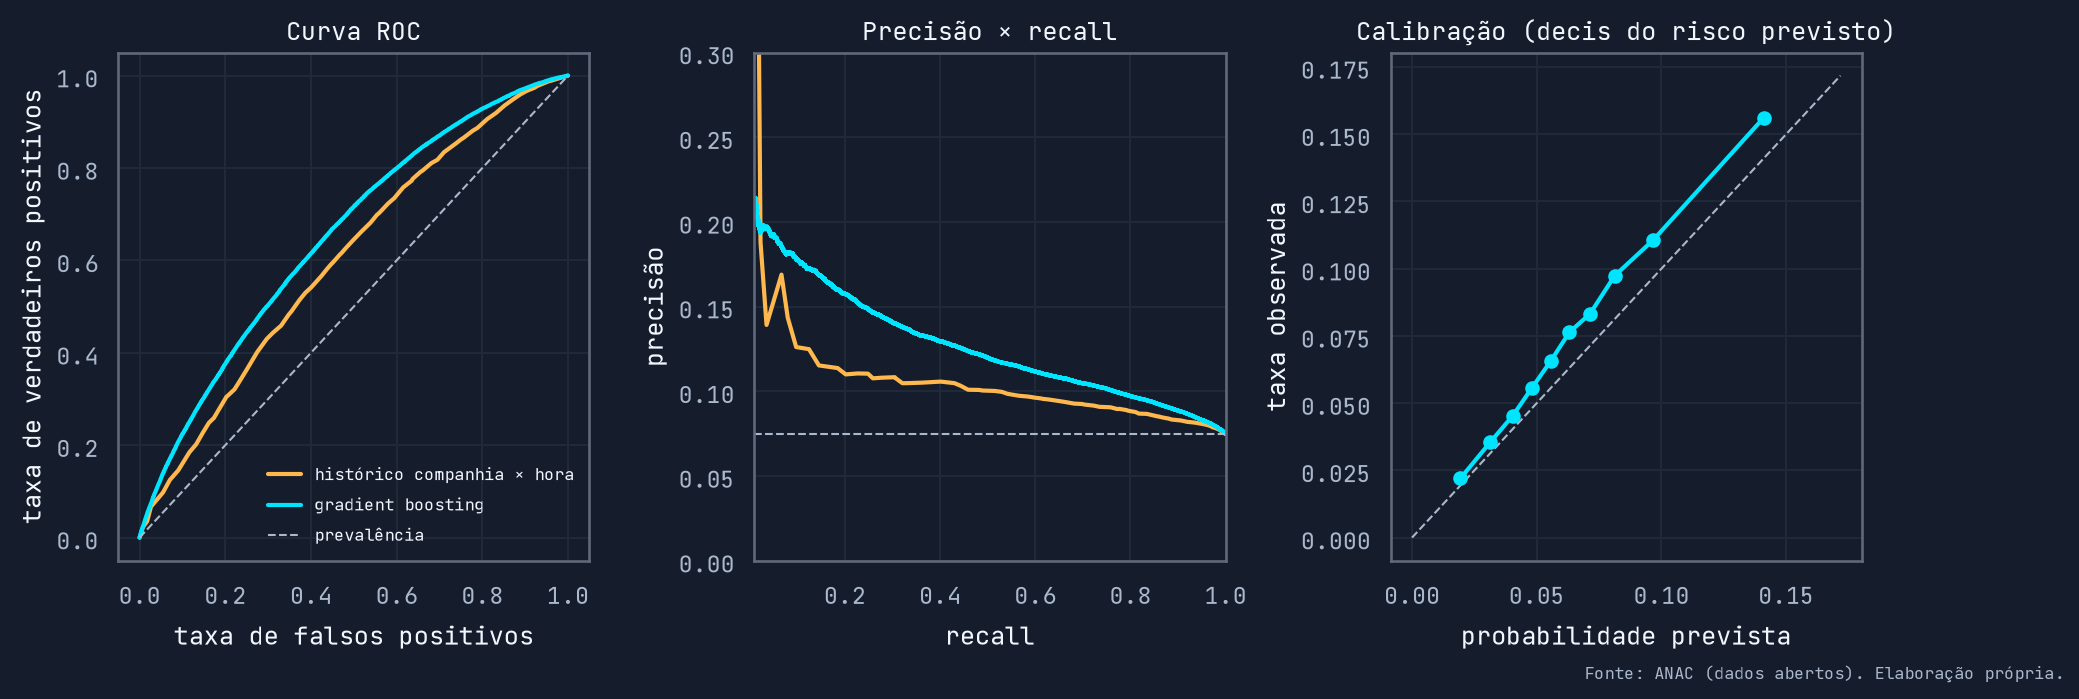

In [35]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.4))
fig.subplots_adjust(wspace=0.35)
series = [('prevalência', p_prev, tema.TEXTO_2), ('histórico companhia × hora', p_hist, tema.AMBAR),
          ('gradient boosting', p_modelo, tema.CIANO)]
for nome, p, cor in series[1:]:
    fpr, tpr, _ = roc_curve(teste.alvo, p)
    axs[0].plot(fpr, tpr, color=cor, lw=2, label=nome)
    prec, rec, _ = precision_recall_curve(teste.alvo, p)
    axs[1].plot(rec, prec, color=cor, lw=2, label=nome)
axs[0].plot([0, 1], [0, 1], color=tema.TEXTO_2, ls='--', lw=1, label='prevalência')
axs[1].axhline(teste.alvo.mean(), color=tema.TEXTO_2, ls='--', lw=1, label='prevalência')
axs[0].set(title='Curva ROC', xlabel='taxa de falsos positivos', ylabel='taxa de verdadeiros positivos')
axs[1].set(title='Precisão × recall', xlabel='recall', ylabel='precisão', ylim=(0, 0.3), xlim=(0.01, 1))
faixas = pd.qcut(p_modelo, 10, labels=False, duplicates='drop')
calib = pd.DataFrame({'previsto': p_modelo, 'observado': teste.alvo.to_numpy(), 'faixa': faixas}).groupby('faixa').mean()
axs[2].plot([0, calib.max().max() * 1.1], [0, calib.max().max() * 1.1], color=tema.TEXTO_2, ls='--', lw=1)
axs[2].plot(calib.previsto, calib.observado, 'o-', color=tema.CIANO, lw=2)
axs[2].set(title='Calibração (decis do risco previsto)', xlabel='probabilidade prevista', ylabel='taxa observada')
axs[0].legend(frameon=False, fontsize=8)
fonte(fig)
plt.show()

### 10.4 O que o modelo entrega na prática

In [36]:
decil = pd.qcut(p_modelo, 10, labels=range(1, 11))
lift = pd.DataFrame({'decil_de_risco': decil, 'alvo': teste.alvo.to_numpy()}).groupby('decil_de_risco', observed=True).alvo.agg(['mean', 'size'])
lift['taxa_atraso_%'] = 100 * lift['mean']
lift['lift'] = lift['mean'] / teste.alvo.mean()
captura_top10 = lift.loc[10, 'mean'] * lift.loc[10, 'size'] / teste.alvo.sum()
print(f'10 % dos voos com maior risco: taxa de atraso de {br(lift.loc[10, "taxa_atraso_%"])} % '
      f'(lift {br(lift.loc[10, "lift"], 2)}×) e {br(100 * captura_top10)} % de todos os atrasos > 30 min')

amostra = teste.sample(60_000, random_state=SEMENTE)
imp = permutation_importance(modelo, amostra[VARIAVEIS], amostra.alvo, scoring='roc_auc', n_repeats=3, random_state=SEMENTE)
importancia = pd.DataFrame({'variável': VARIAVEIS, 'queda_no_ROC_AUC': imp.importances_mean}).sort_values('queda_no_ROC_AUC', ascending=False)
tabela(lift[['size', 'taxa_atraso_%', 'lift']].reset_index().rename(columns={'size': 'voos'}), 2)

10 % dos voos com maior risco: taxa de atraso de 15,6 % (lift 2,09×) e 20,9 % de todos os atrasos > 30 min


,decil_de_risco,voos,taxa_atraso_%,lift
0,1,50.904,"2,20","0,29"
1,2,50.901,"3,55","0,47"
2,3,50.900,"4,54","0,61"
3,4,50.904,"5,58","0,75"
4,5,50.901,"6,56","0,88"
5,6,50.900,"7,64","1,02"
6,7,50.902,"8,32","1,11"
7,8,50.902,"9,74","1,30"
8,9,50.901,"11,05","1,48"
9,10,50.902,"15,62","2,09"


In [37]:
tabela(importancia, 4)

,variável,queda_no_ROC_AUC
3,hora_prevista,"0,0866"
1,origem,"0,0431"
7,partidas_origem_hora,"0,0344"
2,destino,"0,0185"
4,dia_semana,"0,0169"
0,empresa,"0,0140"
5,mes,"0,0125"
8,chegadas_destino_hora,"0,0024"
6,duracao_prevista_min,"0,0014"


⚠️ **O que observar**
- O ganho é **real e modesto**: ROC-AUC perto de 0,65. O atraso depende muito do que acontece no próprio dia (clima, um atraso anterior do mesmo avião, controle de tráfego), que nenhuma variável da malha conhece.
- O modelo serve para **ordenar** voos por risco, não para prever um voo isolado. A ordem dos decis é preservada, mas os pontos ficam um pouco acima da diagonal: em 2026 o modelo subestima levemente o risco, um sinal de mudança em relação ao treino que pede recalibração periódica antes de usar a probabilidade como estimativa de quantos voos vão atrasar.
- A importância por permutação mede o quanto o ROC-AUC cai quando a variável é embaralhada; variáveis correlacionadas (hora e congestionamento) dividem a importância entre si.

## 11. Achados e recomendações

O texto abaixo é montado a partir dos números calculados nas seções anteriores: se os dados mudarem, ele muda junto.

In [38]:
def coef(y, x, modelo='M3'):
    r = coefs[(coefs['reclamações'] == desfechos[y]) & (coefs.modelo == modelo) & (coefs['variável'].str.startswith(x))].iloc[0]
    return r


c_canc = coef('reclamacoes_100k', 'cancel')
c_atr = coef('reclamacoes_100k', 'atraso')
c_atr_m2 = coef('reclamacoes_100k', 'atraso', 'M2')
c_canc_op = coef('reclamacoes_operacionais_100k', 'cancel')
c_atr_op = coef('reclamacoes_operacionais_100k', 'atraso')
c_placebo = coef('reclamacoes_cobranca_100k', 'cancel')
media_recl = painel.reclamacoes_100k.mean()
ordem_conv = conv.sort_values('nao_resolvidas_operacionais_por_mil', ascending=False)
pior, melhor = ordem_conv.index[0], ordem_conv.index[-1]
v_pior, v_melhor = ordem_conv.nao_resolvidas_operacionais_por_mil.iloc[0], ordem_conv.nao_resolvidas_operacionais_por_mil.iloc[-1]
ml = metricas.set_index('modelo')

resumo = {
    'periodo_reclamacoes': 'jan/2023 a dez/2025', 'periodo_voos': 'jan/2023 a ago/2026',
    'voos_analisados': int(painel_completo.voos_previstos.sum()),
    'reclamacoes_analisadas': int(painel.reclamacoes.sum()),
    'cancelamento_coef': c_canc.coef, 'cancelamento_ic': [c_canc.ic95_inf, c_canc.ic95_sup],
    'cancelamento_pct_media': c_canc['efeito_%_da_media'],
    'cancelamento_operacionais_coef': c_canc_op.coef, 'atraso_operacionais_coef': c_atr_op.coef,
    'atraso_operacionais_ic': [c_atr_op.ic95_inf, c_atr_op.ic95_sup],
    'placebo_cobranca_coef': c_placebo.coef, 'placebo_cobranca_ic': [c_placebo.ic95_inf, c_placebo.ic95_sup],
    'atraso_coef_m3': c_atr.coef, 'atraso_ic_m3': [c_atr.ic95_inf, c_atr.ic95_sup], 'atraso_coef_m2': c_atr_m2.coef,
    'r2_controles': r2_controles, 'r2_completo': r2_completo, 'r2_parcial_operacao': r2_parcial,
    'media_reclamacoes_100k': media_recl,
    'conversao_por_mil': conv.nao_resolvidas_operacionais_por_mil.round(2).to_dict(),
    'conversao_ic': {e: [conv.loc[e, 'ic_inf_por_mil'], conv.loc[e, 'ic_sup_por_mil']] for e in conv.index},
    'ml_teste': ml.round(4).to_dict(orient='index'),
    'ml_top10_taxa': lift.loc[10, 'taxa_atraso_%'], 'ml_top10_lift': lift.loc[10, 'lift'], 'ml_top10_captura': 100 * captura_top10,
    'nao_avaliada_2025_pct': nao_avaliada_2025,
}
(PASTA_AGREGADOS / 'resumo.json').write_text(json.dumps(resumo, ensure_ascii=False, indent=1, default=float), encoding='utf-8')

texto = f'''
### Resposta curta

**Cancelamento explica parte das reclamações; atraso quase não.** No modelo mais controlado, cada ponto percentual a mais de voos cancelados num mês acompanha **{br(c_canc.coef)} reclamações a mais por 100 mil passageiros** (IC 95 %: {br(c_canc.ic95_inf)} a {br(c_canc.ic95_sup)}), cerca de {br(c_canc['efeito_%_da_media'], 0)} % da média de {br(media_recl, 0)}. Um ponto a mais de chegadas atrasadas acompanha {br(c_atr.coef, 2)} (IC 95 %: {br(c_atr.ic95_inf, 2)} a {br(c_atr.ic95_sup, 2)}), um efeito que não se distingue de zero no total.

### Três achados

1. **Cancelar custa caro em reclamação; atrasar 15 minutos, pouco.** +1 p.p. de cancelamento → +{br(c_canc.coef)} reclamações/100 mil pax, das quais {br(c_canc_op.coef)} operacionais. Para o atraso, só as reclamações operacionais respondem, e pouco: {br(c_atr_op.coef, 2)} por ponto (IC 95 %: {br(c_atr_op.ic95_inf, 2)} a {br(c_atr_op.ic95_sup, 2)}). O placebo passa: as reclamações de cobrança não respondem ao cancelamento do mês ({br(c_placebo.coef, 2)}; IC 95 %: {br(c_placebo.ic95_inf, 2)} a {br(c_placebo.ic95_sup, 2)}). Com controles mais fracos (modelo M2: companhia, mês e tendência), o atraso parecia valer {br(c_atr_m2.coef, 2)} por ponto, e até as reclamações de cobrança "respondiam" a ele: a associação vinha de choques de cada companhia em cada ano, não da pontualidade.
2. **Quem mais move as reclamações é a companhia no ano, não a operação do mês.** Os efeitos de companhia × ano e de mês do calendário explicam {br(100 * r2_controles, 0)} % da variação; atraso e cancelamento explicam {br(100 * r2_parcial, 0)} % do que sobra. A Azul subiu de {br(taxa_ano.loc['Azul', 2023], 0)} para {br(taxa_ano.loc['Azul', 2025], 0)} reclamações por 100 mil pax entre 2023 e 2025 com pontualidade estável, enquanto a Gol melhorou a pontualidade e caiu de {br(taxa_ano.loc['Gol', 2023], 0)} para {br(taxa_ano.loc['Gol', 2025], 0)}.
3. **A {pior} é quem mais converte problema operacional em reclamação não resolvida:** {br(v_pior)} reclamações operacionais não resolvidas por mil voos cancelados ou atrasados, contra {br(v_melhor)} da {melhor} ({br(100 * (v_pior / v_melhor - 1), 0)} % a mais; IC 95 % da {pior}: {br(conv.loc[pior, 'ic_inf_por_mil'])} a {br(conv.loc[pior, 'ic_sup_por_mil'])}). A diferença vem do volume: cada mil voos com problema da {pior} geram {br(conv.loc[pior, 'operacionais_por_mil_problemas'], 0)} reclamações operacionais, contra {br(conv.loc[melhor, 'operacionais_por_mil_problemas'], 0)} da {melhor}; a fração delas que termina não resolvida é parecida ({br(conv.loc[pior, 'pct_nao_resolvidas_entre_operacionais'])} % e {br(conv.loc[melhor, 'pct_nao_resolvidas_entre_operacionais'])} %). Parte da explicação está no tipo de problema: {br(conv.loc[pior, 'pct_cancelados_entre_problemas'], 0)} % dos voos com problema da {pior} são cancelamentos, contra {br(conv.loc[melhor, 'pct_cancelados_entre_problemas'], 0)} % da {melhor}, e o cancelamento gera mais reclamação que o atraso (achado 1).

### Recomendações

- **Para um diretor de operações:** tratar o cancelamento como o indicador de experiência que mais pesa: na média de {br(painel.passageiros_pagos.mean() / 1e6, 1)} milhões de passageiros por companhia e mês, cada ponto de cancelamento evitado corresponde a cerca de {br(c_canc.coef * painel.passageiros_pagos.mean() / 1e5, 0)} reclamações a menos por mês. O modelo de risco da seção 10 ajuda a escolher onde pôr reserva: os 10 % de voos com maior risco atrasam {br(lift.loc[10, 'taxa_atraso_%'])} % das vezes ({br(lift.loc[10, 'lift'], 1)}× a média) e concentram {br(100 * captura_top10, 0)} % dos atrasos de mais de 30 minutos.
- **Para o regulador (ANAC e Senacon):** voltar a exigir o código de justificativa no VRA. Sem ele, não dá para separar atraso por clima de atraso por gestão, nem cobrar a companhia só pelo que ela controla. E acompanhar, além da taxa de reclamação, a **conversão de voo com problema em reclamação não resolvida**, que diferencia as companhias onde a pontualidade não diferencia.
'''
display(Markdown(texto))


### Resposta curta

**Cancelamento explica parte das reclamações; atraso quase não.** No modelo mais controlado, cada ponto percentual a mais de voos cancelados num mês acompanha **7,0 reclamações a mais por 100 mil passageiros** (IC 95 %: 3,0 a 11,0), cerca de 9 % da média de 80. Um ponto a mais de chegadas atrasadas acompanha 0,41 (IC 95 %: -0,55 a 1,37), um efeito que não se distingue de zero no total.

### Três achados

1. **Cancelar custa caro em reclamação; atrasar 15 minutos, pouco.** +1 p.p. de cancelamento → +7,0 reclamações/100 mil pax, das quais 2,5 operacionais. Para o atraso, só as reclamações operacionais respondem, e pouco: 0,24 por ponto (IC 95 %: 0,04 a 0,44). O placebo passa: as reclamações de cobrança não respondem ao cancelamento do mês (0,79; IC 95 %: -0,59 a 2,17). Com controles mais fracos (modelo M2: companhia, mês e tendência), o atraso parecia valer 2,81 por ponto, e até as reclamações de cobrança "respondiam" a ele: a associação vinha de choques de cada companhia em cada ano, não da pontualidade.
2. **Quem mais move as reclamações é a companhia no ano, não a operação do mês.** Os efeitos de companhia × ano e de mês do calendário explicam 81 % da variação; atraso e cancelamento explicam 28 % do que sobra. A Azul subiu de 71 para 120 reclamações por 100 mil pax entre 2023 e 2025 com pontualidade estável, enquanto a Gol melhorou a pontualidade e caiu de 82 para 57.
3. **A Azul é quem mais converte problema operacional em reclamação não resolvida:** 19,8 reclamações operacionais não resolvidas por mil voos cancelados ou atrasados, contra 15,6 da LATAM (27 % a mais; IC 95 % da Azul: 19,1 a 20,5). A diferença vem do volume: cada mil voos com problema da Azul geram 148 reclamações operacionais, contra 116 da LATAM; a fração delas que termina não resolvida é parecida (13,4 % e 13,4 %). Parte da explicação está no tipo de problema: 15 % dos voos com problema da Azul são cancelamentos, contra 10 % da LATAM, e o cancelamento gera mais reclamação que o atraso (achado 1).

### Recomendações

- **Para um diretor de operações:** tratar o cancelamento como o indicador de experiência que mais pesa: na média de 2,8 milhões de passageiros por companhia e mês, cada ponto de cancelamento evitado corresponde a cerca de 194 reclamações a menos por mês. O modelo de risco da seção 10 ajuda a escolher onde pôr reserva: os 10 % de voos com maior risco atrasam 15,6 % das vezes (2,1× a média) e concentram 21 % dos atrasos de mais de 30 minutos.
- **Para o regulador (ANAC e Senacon):** voltar a exigir o código de justificativa no VRA. Sem ele, não dá para separar atraso por clima de atraso por gestão, nem cobrar a companhia só pelo que ela controla. E acompanhar, além da taxa de reclamação, a **conversão de voo com problema em reclamação não resolvida**, que diferencia as companhias onde a pontualidade não diferencia.


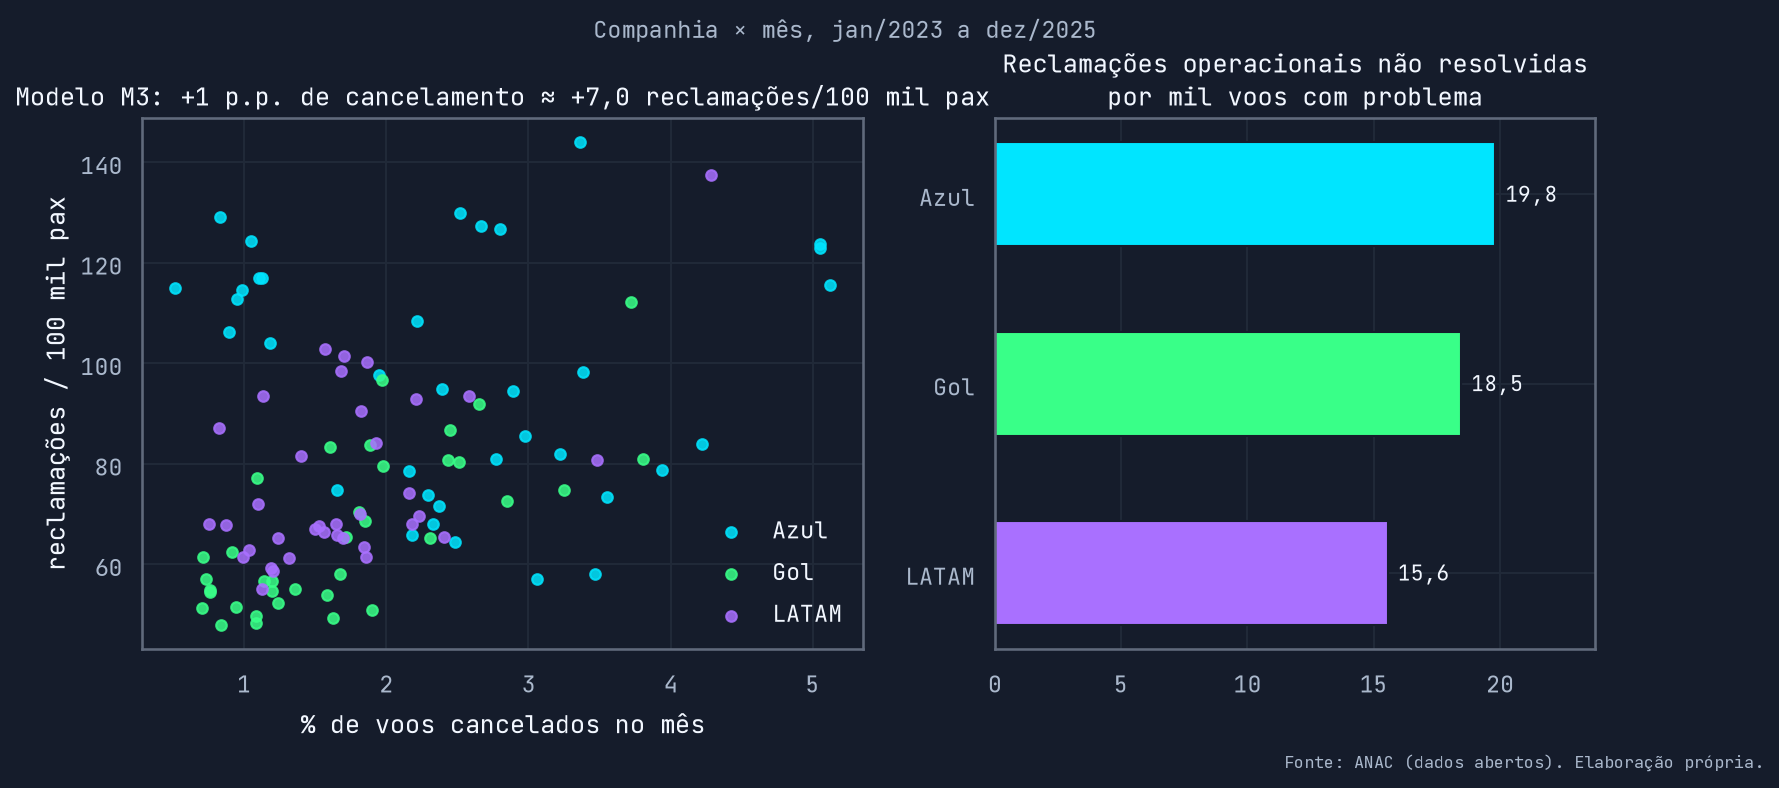

In [39]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={'width_ratios': [1.2, 1]})
for emp in EMPRESAS:
    d = painel[painel.empresa == emp]
    ax1.scatter(d.pct_cancelados, d.reclamacoes_100k, color=CORES[emp], s=26, alpha=0.85, label=emp)
ax1.set(title=f'Modelo M3: +1 p.p. de cancelamento ≈ +{br(c_canc.coef)} reclamações/100 mil pax',
        xlabel='% de voos cancelados no mês', ylabel='reclamações / 100 mil pax')
ax1.legend(frameon=False)
ordem = conv.sort_values('nao_resolvidas_operacionais_por_mil').index
v = conv.loc[ordem, 'nao_resolvidas_operacionais_por_mil']
ax2.barh(range(len(ordem)), v, color=[CORES[e] for e in ordem], height=0.55)
for yi, vi in enumerate(v):
    ax2.text(vi + 0.4, yi, br(vi), va='center', color=tema.TEXTO, fontsize=10)
ax2.set_yticks(range(len(ordem)), ordem)
ax2.set(title='Reclamações operacionais não resolvidas\npor mil voos com problema', xlim=(0, v.max() * 1.2))
fig.suptitle('Companhia × mês, jan/2023 a dez/2025', y=1.03, fontsize=11, color=tema.TEXTO_2)
fonte(fig)
plt.show()

## 12. Limites

In [40]:
display(Markdown(f'''
- **Sem causa do atraso.** O "Código Justificativa" está "N/A" em 100 % dos voos (deixou de ser exigido em abril de 2020). Não dá para separar clima, tráfego aéreo e manutenção.
- **Ligação só no agregado.** Voos e reclamações se encontram no nível companhia × mês; as conclusões valem para meses e companhias, não para passageiros (risco de falácia ecológica).
- **Reclamação voluntária.** O consumidor.gov.br só tem empresas participantes e quem escolheu reclamar ali; Procon, Justiça e redes sociais ficam de fora.
- **Avaliação incompleta.** {br(nao_avaliada_2025)} % das reclamações de 2025 terminaram "Não Avaliada"; "resolvida" e "não resolvida" valem só para a parte avaliada.
- **Painel curto.** 108 observações (3 companhias × 36 meses), porque as reclamações publicadas vão só até dezembro de 2025. Os intervalos de confiança refletem isso.
- **Qualidade do VRA.** Os horários reais ausentes correspondem aos voos cancelados; {br(int(qualidade.corrigidos_virada_dia.sum()), 0)} voos tiveram a virada de dia corrigida e {br(int(qualidade.implausiveis_excluidos.sum()), 0)} com atraso implausível saíram dos KPIs de pontualidade.
- **Denominador misto.** Reclamações por 100 mil passageiros usam o total de passageiros pagos (doméstico e internacional), enquanto a pontualidade usa só os voos domésticos.
- **Modelo de risco.** Usa apenas a malha; o desempenho de teste vale para jan–ago/2026 e precisa ser reavaliado com dados novos.
'''))


- **Sem causa do atraso.** O "Código Justificativa" está "N/A" em 100 % dos voos (deixou de ser exigido em abril de 2020). Não dá para separar clima, tráfego aéreo e manutenção.
- **Ligação só no agregado.** Voos e reclamações se encontram no nível companhia × mês; as conclusões valem para meses e companhias, não para passageiros (risco de falácia ecológica).
- **Reclamação voluntária.** O consumidor.gov.br só tem empresas participantes e quem escolheu reclamar ali; Procon, Justiça e redes sociais ficam de fora.
- **Avaliação incompleta.** 49,6 % das reclamações de 2025 terminaram "Não Avaliada"; "resolvida" e "não resolvida" valem só para a parte avaliada.
- **Painel curto.** 108 observações (3 companhias × 36 meses), porque as reclamações publicadas vão só até dezembro de 2025. Os intervalos de confiança refletem isso.
- **Qualidade do VRA.** Os horários reais ausentes correspondem aos voos cancelados; 391 voos tiveram a virada de dia corrigida e 84 com atraso implausível saíram dos KPIs de pontualidade.
- **Denominador misto.** Reclamações por 100 mil passageiros usam o total de passageiros pagos (doméstico e internacional), enquanto a pontualidade usa só os voos domésticos.
- **Modelo de risco.** Usa apenas a malha; o desempenho de teste vale para jan–ago/2026 e precisa ser reavaliado com dados novos.


---
Fonte: ANAC (dados abertos): Voo Regular Ativo (VRA), Dados Estatísticos do Transporte Aéreo e reclamações do consumidor.gov.br. Uso livre com crédito à fonte (Decreto 8.777/2016, art. 2º, III). Elaboração: Fernando Figueiredo, *Manual de Análise de Dados*.